In [1]:
from pathlib import Path

required_files = [
    "assessments.csv",
    "courses.csv",
    "studentAssessment.csv",
    "studentInfo.csv",
    "studentRegistration.csv",
    "studentVle.csv",
    "vle.csv"
]

file_paths = {}

for filename in required_files:
    matches = list(Path(".").rglob(filename))
    file_paths[filename] = matches[0] if matches else None

for filename, path in file_paths.items():
    print(f"{filename:25} -> {path}")


assessments.csv           -> Dataset\assessments.csv
courses.csv               -> Dataset\courses.csv
studentAssessment.csv     -> Dataset\studentAssessment.csv
studentInfo.csv           -> Dataset\studentInfo.csv
studentRegistration.csv   -> Dataset\studentRegistration.csv
studentVle.csv            -> Dataset\studentVle.csv
vle.csv                   -> Dataset\vle.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

assessments = pd.read_csv(file_paths["assessments.csv"])
courses = pd.read_csv(file_paths["courses.csv"])
student_assessment = pd.read_csv(file_paths["studentAssessment.csv"])
student_info = pd.read_csv(file_paths["studentInfo.csv"])
student_registration = pd.read_csv(file_paths["studentRegistration.csv"])
vle = pd.read_csv(file_paths["vle.csv"])

tables = {
    "assessments": assessments,
    "courses": courses,
    "studentAssessment": student_assessment,
    "studentInfo": student_info,
    "studentRegistration": student_registration,
    "vle": vle
}

for name, table in tables.items():
    print(f"{name:22} rows: {table.shape[0]:>8,}   columns: {table.shape[1]}")


assessments            rows:      206   columns: 6
courses                rows:       22   columns: 3
studentAssessment      rows:  173,912   columns: 5
studentInfo            rows:   32,593   columns: 12
studentRegistration    rows:   32,593   columns: 5
vle                    rows:    6,364   columns: 6


In [3]:
for name, table in tables.items():
    print(f"\n{name}")
    print("-" * len(name))
    
    column_summary = pd.DataFrame({
        "column": table.columns,
        "data_type": table.dtypes.astype(str).values
    })
    
    display(column_summary)


assessments
-----------


,column,data_type
0,code_module,str
1,code_presentation,str
2,id_assessment,int64
3,assessment_type,str
4,date,str
5,weight,float64



courses
-------


,column,data_type
0,code_module,str
1,code_presentation,str
2,module_presentation_length,int64



studentAssessment
-----------------


,column,data_type
0,id_assessment,int64
1,id_student,int64
2,date_submitted,int64
3,is_banked,int64
4,score,str


... (2 outputs left out)


studentRegistration
-------------------


,column,data_type
0,code_module,str
1,code_presentation,str
2,id_student,int64
3,date_registration,str
4,date_unregistration,str



vle
---


,column,data_type
0,id_site,int64
1,code_module,str
2,code_presentation,str
3,activity_type,str
4,week_from,str
5,week_to,str


In [4]:
missing_summary = []

for table_name, table in tables.items():
    for column in table.columns:
        question_marks = table[column].astype(str).str.strip().eq("?").sum()
        standard_missing = table[column].isna().sum()
        
        if question_marks > 0 or standard_missing > 0:
            missing_summary.append({
                "table": table_name,
                "column": column,
                "question_marks": question_marks,
                "standard_missing": standard_missing,
                "total_missing": question_marks + standard_missing
            })

missing_summary = pd.DataFrame(missing_summary)

display(missing_summary)

,table,column,question_marks,standard_missing,total_missing
0,assessments,date,11,0,11
1,studentAssessment,score,173,0,173
2,studentInfo,imd_band,1111,0,1111
3,studentRegistration,date_registration,45,0,45
4,studentRegistration,date_unregistration,22521,0,22521
5,vle,week_from,5243,0,5243
6,vle,week_to,5243,0,5243


In [5]:
# Replace OULAD's "?" marker with proper missing values
for table in tables.values():
    table.replace("?", np.nan, inplace=True)

# Convert columns that should be numeric
assessments["date"] = pd.to_numeric(
    assessments["date"], errors="coerce"
)

student_assessment["score"] = pd.to_numeric(
    student_assessment["score"], errors="coerce"
)

student_registration["date_registration"] = pd.to_numeric(
    student_registration["date_registration"], errors="coerce"
)

student_registration["date_unregistration"] = pd.to_numeric(
    student_registration["date_unregistration"], errors="coerce"
)

vle["week_from"] = pd.to_numeric(
    vle["week_from"], errors="coerce"
)

vle["week_to"] = pd.to_numeric(
    vle["week_to"], errors="coerce"
)

print("Updated data types:\n")
print("assessments.date:", assessments["date"].dtype)
print("studentAssessment.score:", student_assessment["score"].dtype)
print(
    "studentRegistration.date_registration:",
    student_registration["date_registration"].dtype
)
print(
    "studentRegistration.date_unregistration:",
    student_registration["date_unregistration"].dtype
)
print("vle.week_from:", vle["week_from"].dtype)
print("vle.week_to:", vle["week_to"].dtype)

Updated data types:

assessments.date: float64
studentAssessment.score: float64
studentRegistration.date_registration: float64
studentRegistration.date_unregistration: float64
vle.week_from: float64
vle.week_to: float64


In [6]:
key_checks = {
    "courses": [
        "code_module",
        "code_presentation"
    ],
    "assessments": [
        "id_assessment"
    ],
    "studentInfo": [
        "code_module",
        "code_presentation",
        "id_student"
    ],
    "studentRegistration": [
        "code_module",
        "code_presentation",
        "id_student"
    ],
    "vle": [
        "code_module",
        "code_presentation",
        "id_site"
    ],
    "studentAssessment": [
        "id_assessment",
        "id_student"
    ]
}

duplicate_results = []

for table_name, key_columns in key_checks.items():
    table = tables[table_name]
    
    duplicate_results.append({
        "table": table_name,
        "key": " + ".join(key_columns),
        "duplicate_key_rows": table.duplicated(
            subset=key_columns,
            keep=False
        ).sum(),
        "exact_duplicate_rows": table.duplicated(
            keep=False
        ).sum()
    })

duplicate_results = pd.DataFrame(duplicate_results)

display(duplicate_results)

,table,key,duplicate_key_rows,exact_duplicate_rows
0,courses,code_module + code_presentation,0,0
1,assessments,id_assessment,0,0
2,studentInfo,code_module + code_presentation + id_student,0,0
3,studentRegistration,code_module + code_presentation + id_student,0,0
4,vle,code_module + code_presentation + id_site,0,0
5,studentAssessment,id_assessment + id_student,0,0


In [7]:
registration_keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

analysis_data = student_info.merge(
    student_registration,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

# Keep students still enrolled after the first four weeks
prediction_cohort = analysis_data[
    analysis_data["date_unregistration"].isna()
    | (analysis_data["date_unregistration"] > 27)
].copy()

# Create the binary target
prediction_cohort["at_risk"] = (
    prediction_cohort["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)

print(f"All registrations: {len(analysis_data):,}")
print(f"Excluded because withdrawal was known by day 27: "
      f"{len(analysis_data) - len(prediction_cohort):,}")
print(f"Final prediction cohort: {len(prediction_cohort):,}")

print("\nFinal outcomes in the prediction cohort:")
display(
    prediction_cohort["final_result"]
    .value_counts()
    .to_frame("registrations")
)

print("\nBinary target:")
display(
    prediction_cohort["at_risk"]
    .value_counts()
    .rename(index={0: "Successful", 1: "At risk"})
    .to_frame("registrations")
)

All registrations: 32,593
Excluded because withdrawal was known by day 27: 5,040
Final prediction cohort: 27,553

Final outcomes in the prediction cohort:


,registrations
final_result,
Pass,12361
Fail,7044
Withdrawn,5124
Distinction,3024



Binary target:


,registrations
at_risk,
Successful,15385
At risk,12168


,registrations,percentage
at_risk,,
Successful,15385,55.84
At risk,12168,44.16


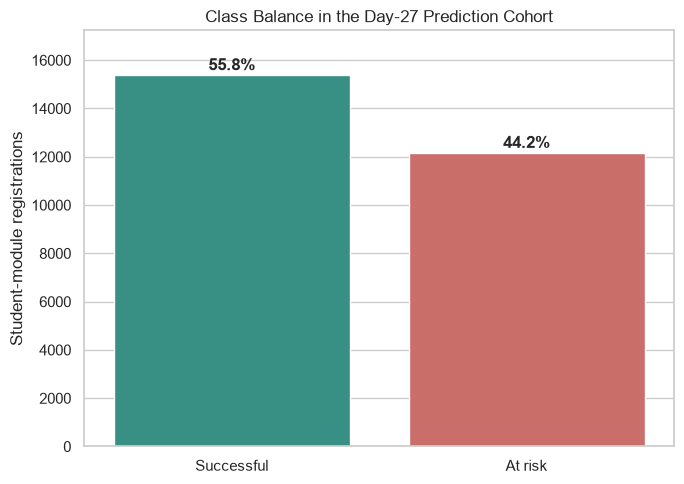

In [8]:
class_summary = (
    prediction_cohort["at_risk"]
    .value_counts()
    .rename(index={0: "Successful", 1: "At risk"})
    .reindex(["Successful", "At risk"])
    .to_frame("registrations")
)

class_summary["percentage"] = (
    class_summary["registrations"]
    / class_summary["registrations"].sum()
    * 100
)

display(class_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=class_summary.index,
    y=class_summary["registrations"],
    hue=class_summary.index,
    palette={
        "Successful": "#2A9D8F",
        "At risk": "#D95F59"
    },
    legend=False
)

for bar, percentage in zip(ax.patches, class_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{percentage:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("Class Balance in the Day-27 Prediction Cohort")
plt.xlabel("")
plt.ylabel("Student-module registrations")
plt.ylim(0, class_summary["registrations"].max() * 1.12)
plt.tight_layout()
plt.show()

,gender,registrations,at_risk_students,at_risk_rate
0,F,12373,5244,42.38
1,M,15180,6924,45.61


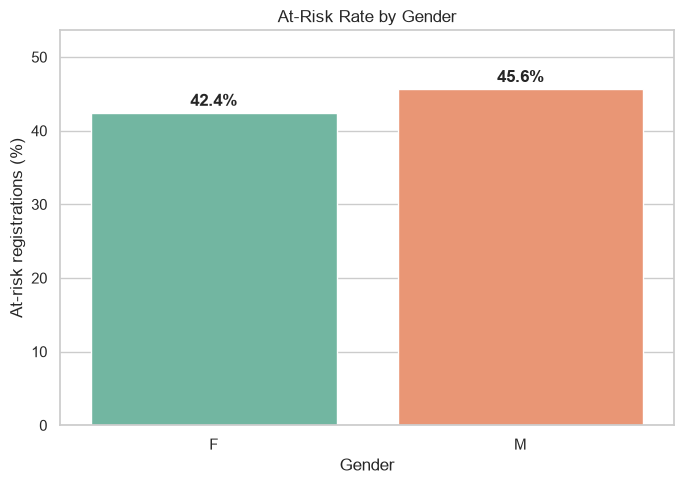

In [9]:
gender_summary = (
    prediction_cohort
    .groupby("gender")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

gender_summary["at_risk_rate"] *= 100

display(gender_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_summary,
    x="gender",
    y="at_risk_rate",
    hue="gender",
    palette="Set2",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, gender_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,age_band_label,registrations,at_risk_students,at_risk_rate
0,Under 35,19187,8855,46.15
1,35-54,8173,3253,39.80
2,55 and older,193,60,31.09


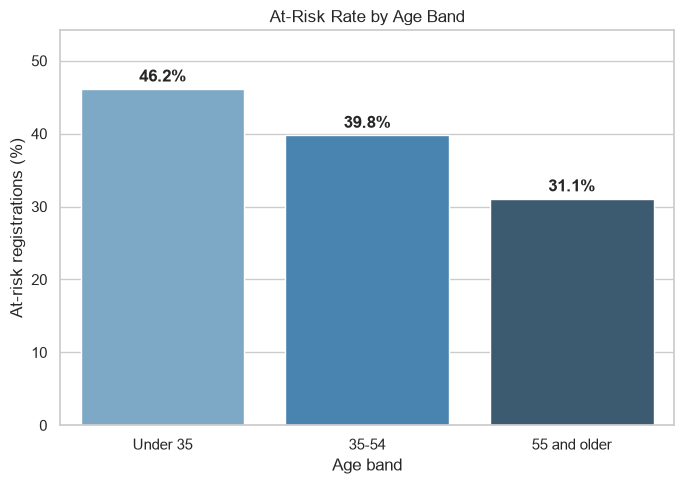

In [10]:
age_order = ["Under 35", "35-54", "55 and older"]

# Readable labels in a separate column, so the original age_band values are kept
prediction_cohort["age_band_label"] = prediction_cohort["age_band"].replace({
    "0-35": "Under 35",
    "35-55": "35-54",
    "55<=": "55 and older"
})

age_summary = (
    prediction_cohort
    .groupby("age_band_label", observed=True)
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reindex(age_order)
    .reset_index()
)

age_summary["at_risk_rate"] *= 100

display(age_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=age_summary,
    x="age_band_label",
    y="at_risk_rate",
    hue="age_band_label",
    palette="Blues_d",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Age Band")
plt.xlabel("Age band")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, age_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,disability,disability_label,registrations,at_risk_students,at_risk_rate
0,N,No,24937,10759,43.14
1,Y,Yes,2616,1409,53.86


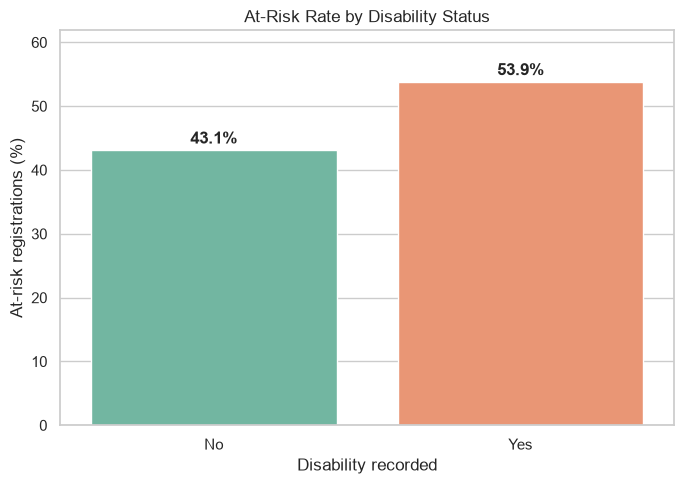

In [11]:
disability_summary = (
    prediction_cohort
    .groupby("disability")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

disability_summary["at_risk_rate"] *= 100

disability_summary["disability_label"] = (
    disability_summary["disability"]
    .map({"N": "No", "Y": "Yes"})
)

display(
    disability_summary[
        [
            "disability",
            "disability_label",
            "registrations",
            "at_risk_students",
            "at_risk_rate"
        ]
    ].round(2)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=disability_summary,
    x="disability_label",
    y="at_risk_rate",
    hue="disability_label",
    palette="Set2",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Disability Status")
plt.xlabel("Disability recorded")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, disability_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,imd_band_clean,registrations,at_risk_students,at_risk_rate
0,0-10%,2651,1487,56.09
1,10-20%,2828,1470,51.98
2,20-30%,2988,1499,50.17
3,30-40%,3000,1340,44.67
4,40-50%,2715,1198,44.13
5,50-60%,2690,1166,43.35
6,60-70%,2512,1004,39.97
7,70-80%,2520,1037,41.15
8,80-90%,2380,887,37.27
9,90-100%,2240,781,34.87


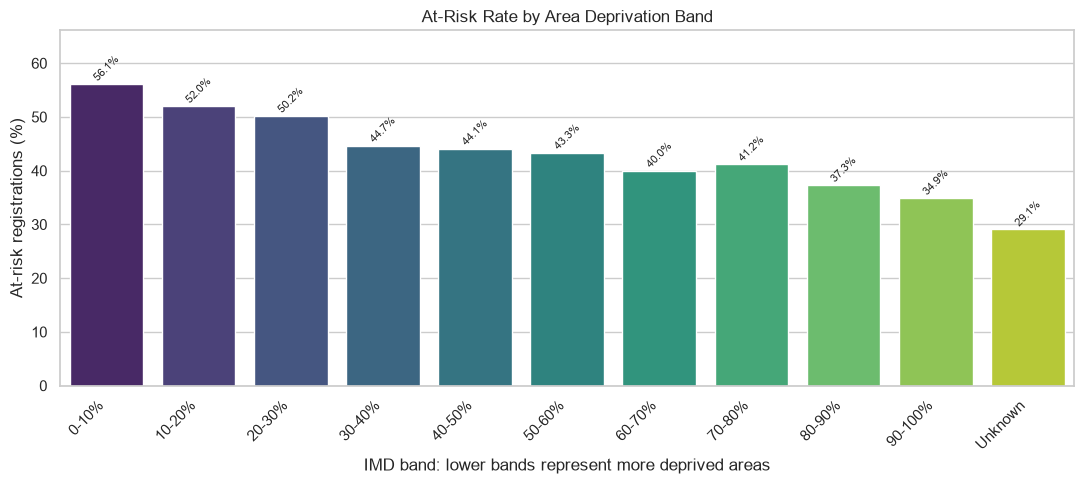

In [12]:

imd_order = [
    "0-10%",
    "10-20%",
    "20-30%",
    "30-40%",
    "40-50%",
    "50-60%",
    "60-70%",
    "70-80%",
    "80-90%",
    "90-100%",
    "Unknown"
]

prediction_cohort["imd_band_clean"] = (
    prediction_cohort["imd_band"]
    .fillna("Unknown")
    .replace({"10-20": "10-20%"})
)

imd_summary = (
    prediction_cohort
    .groupby("imd_band_clean")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reindex(imd_order, fill_value=0)
    .reset_index()
)

imd_summary["at_risk_rate"] *= 100

display(imd_summary.round(2))

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=imd_summary,
    x="imd_band_clean",
    y="at_risk_rate",
    hue="imd_band_clean",
    palette="viridis",
    legend=False
)

for bar in ax.patches:
    if bar.get_height() > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.6,
            f"{bar.get_height():.1f}%",
            ha="center",
            fontsize=8,
            rotation=45
        )

plt.title("At-Risk Rate by Area Deprivation Band")
plt.xlabel("IMD band: lower bands represent more deprived areas")
plt.ylabel("At-risk registrations (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(1, imd_summary["at_risk_rate"].max() + 10))
plt.tight_layout()
plt.show()


,highest_education,registrations,at_risk_students,at_risk_rate
0,No Formal quals,260,157,60.38
1,Lower Than A Level,10808,5696,52.70
2,A Level or Equivalent,12045,4737,39.33
3,HE Qualification,4152,1495,36.01
4,Post Graduate Qualification,288,83,28.82


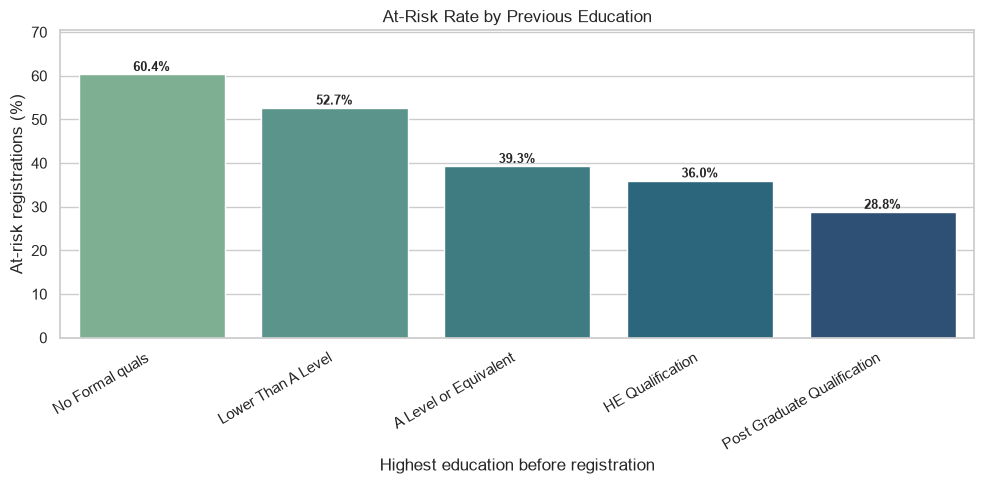

In [13]:
education_order = [
    "No Formal quals",
    "Lower Than A Level",
    "A Level or Equivalent",
    "HE Qualification",
    "Post Graduate Qualification"
]

education_summary = (
    prediction_cohort
    .groupby("highest_education")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reindex(education_order)
    .reset_index()
)

education_summary["at_risk_rate"] *= 100

display(education_summary.round(2))

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=education_summary,
    x="highest_education",
    y="at_risk_rate",
    hue="highest_education",
    palette="crest",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("At-Risk Rate by Previous Education")
plt.xlabel("Highest education before registration")
plt.ylabel("At-risk registrations (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, education_summary["at_risk_rate"].max() + 10)
plt.tight_layout()
plt.show()

,previous_attempt_group,registrations,at_risk_students,at_risk_rate
0,0,24073,10068,41.82
1,1,2770,1630,58.84
2,2+,710,470,66.20


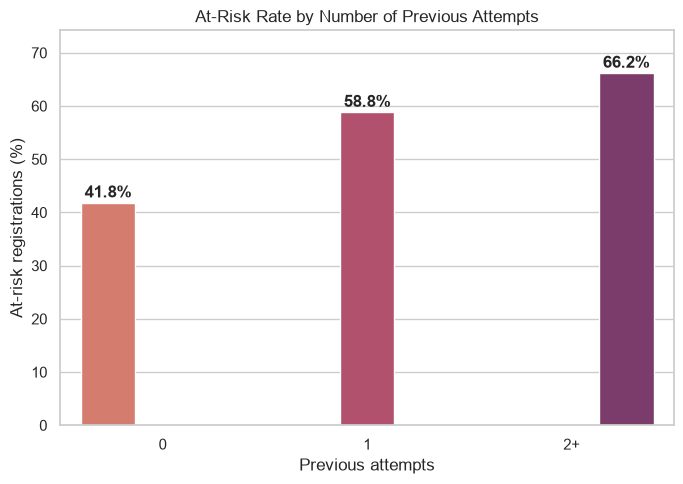

In [14]:
prediction_cohort["previous_attempt_group"] = pd.cut(
    prediction_cohort["num_of_prev_attempts"],
    bins=[-1, 0, 1, np.inf],
    labels=["0", "1", "2+"]
)

attempt_summary = (
    prediction_cohort
    .groupby("previous_attempt_group", observed=True)
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

attempt_summary["at_risk_rate"] *= 100

display(attempt_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=attempt_summary,
    x="previous_attempt_group",
    y="at_risk_rate",
    hue="previous_attempt_group",
    palette="flare",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Number of Previous Attempts")
plt.xlabel("Previous attempts")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, attempt_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,credit_band,registrations,at_risk_students,at_risk_rate
0,Up to 60,18315,7661,41.83
1,61-120,7673,3627,47.27
2,121-180,1241,682,54.96
3,More than 180,324,198,61.11


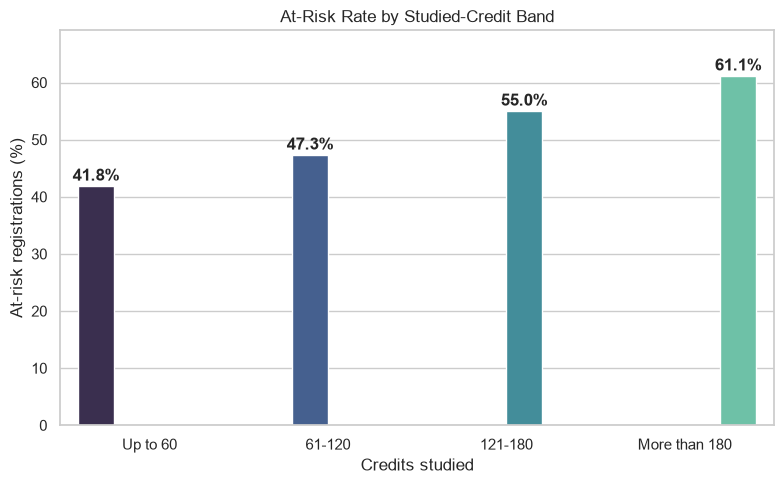

In [15]:
prediction_cohort["credit_band"] = pd.cut(
    prediction_cohort["studied_credits"],
    bins=[-np.inf, 60, 120, 180, np.inf],
    labels=["Up to 60", "61-120", "121-180", "More than 180"]
)

credit_summary = (
    prediction_cohort
    .groupby("credit_band", observed=True)
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

credit_summary["at_risk_rate"] *= 100

display(credit_summary.round(2))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=credit_summary,
    x="credit_band",
    y="at_risk_rate",
    hue="credit_band",
    palette="mako",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Studied-Credit Band")
plt.xlabel("Credits studied")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, credit_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,code_module,registrations,at_risk_students,at_risk_rate
2,CCC,3523,1845,52.37
3,DDD,5287,2677,50.63
5,FFF,6599,2951,44.72
1,BBB,6435,2681,41.66
6,GGG,2438,924,37.90
4,EEE,2553,903,35.37
0,AAA,718,187,26.04


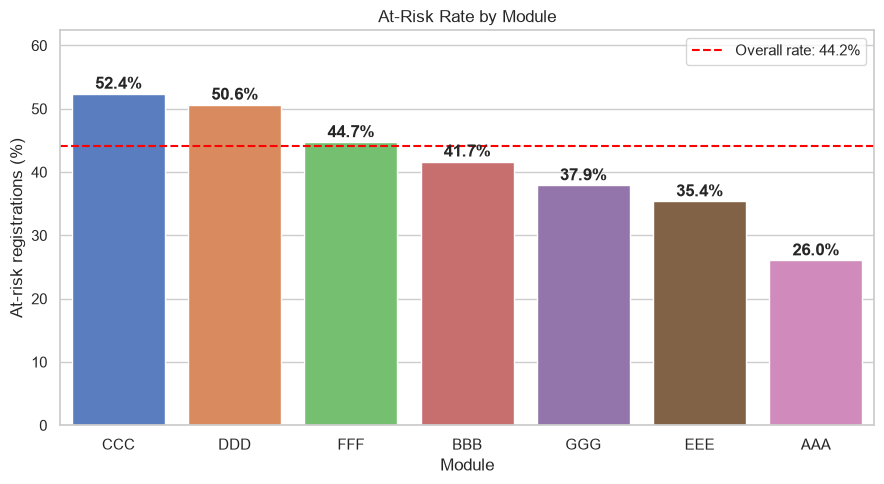

In [16]:
module_summary = (
    prediction_cohort
    .groupby("code_module")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
    .sort_values("at_risk_rate", ascending=False)
)

module_summary["at_risk_rate"] *= 100

overall_risk_rate = prediction_cohort["at_risk"].mean() * 100

display(module_summary.round(2))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=module_summary,
    x="code_module",
    y="at_risk_rate",
    hue="code_module",
    palette="muted",
    legend=False
)

plt.axhline(
    overall_risk_rate,
    color="red",
    linestyle="--",
    label=f"Overall rate: {overall_risk_rate:.1f}%"
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Module")
plt.xlabel("Module")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, module_summary["at_risk_rate"].max() + 10)
plt.legend()
plt.tight_layout()
plt.show()

,module_presentation,registrations,at_risk_students,at_risk_rate
6,CCC_2014B,1500,837,55.80
8,DDD_2013B,1146,636,55.50
10,DDD_2014B,1030,551,53.50
7,CCC_2014J,2023,1008,49.83
17,FFF_2014B,1302,648,49.77
9,DDD_2013J,1648,819,49.70
2,BBB_2013B,1531,728,47.55
15,FFF_2013B,1454,672,46.22
11,DDD_2014J,1463,671,45.86
16,FFF_2013J,1983,888,44.78


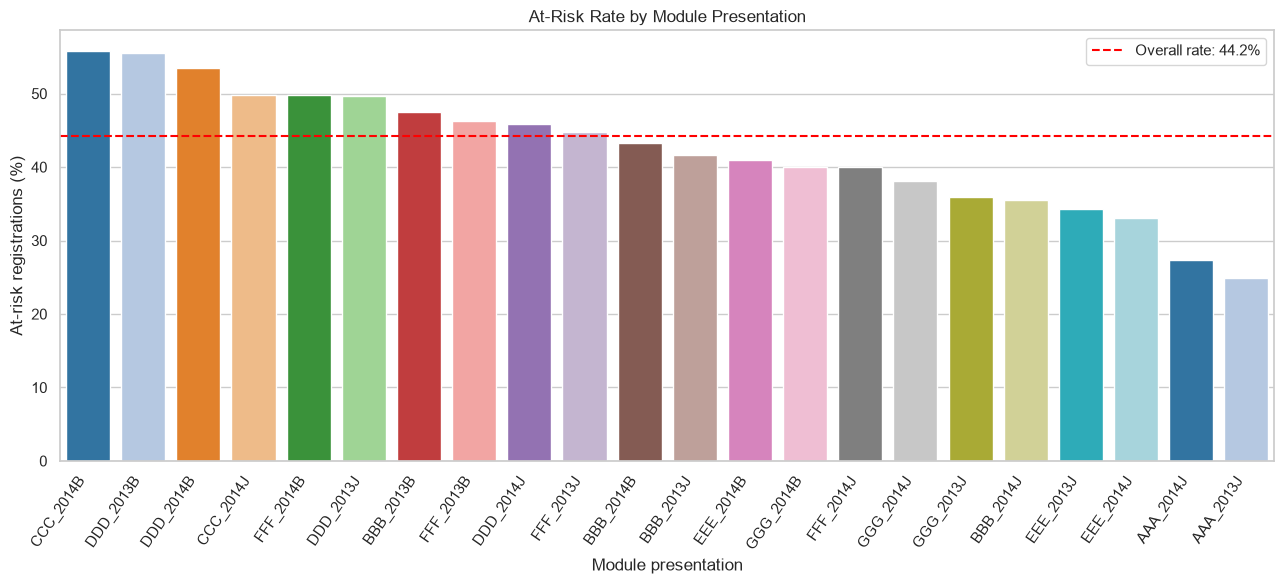

In [17]:
prediction_cohort["module_presentation"] = (
    prediction_cohort["code_module"]
    + "_"
    + prediction_cohort["code_presentation"]
)

presentation_summary = (
    prediction_cohort
    .groupby("module_presentation")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
    .sort_values("at_risk_rate", ascending=False)
)

presentation_summary["at_risk_rate"] *= 100

display(presentation_summary.round(2))

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=presentation_summary,
    x="module_presentation",
    y="at_risk_rate",
    hue="module_presentation",
    palette="tab20",
    legend=False
)

plt.axhline(
    overall_risk_rate,
    color="red",
    linestyle="--",
    label=f"Overall rate: {overall_risk_rate:.1f}%"
)

plt.title("At-Risk Rate by Module Presentation")
plt.xlabel("Module presentation")
plt.ylabel("At-risk registrations (%)")
plt.xticks(rotation=55, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
early_assessment_schedule = (
    assessments[
        assessments["date"].between(0, 27, inclusive="both")
    ]
    .groupby(
        ["code_module", "code_presentation"]
    )
    .agg(
        early_assessments=("id_assessment", "nunique"),
        earliest_deadline=("date", "min"),
        latest_deadline=("date", "max")
    )
    .reset_index()
)

assessment_opportunities = courses[
    ["code_module", "code_presentation"]
].merge(
    early_assessment_schedule,
    on=["code_module", "code_presentation"],
    how="left",
    validate="one_to_one"
)

assessment_opportunities["early_assessments"] = (
    assessment_opportunities["early_assessments"]
    .fillna(0)
    .astype(int)
)

assessment_opportunities["module_presentation"] = (
    assessment_opportunities["code_module"]
    + "_"
    + assessment_opportunities["code_presentation"]
)

display(
    assessment_opportunities[
        [
            "module_presentation",
            "early_assessments",
            "earliest_deadline",
            "latest_deadline"
        ]
    ].sort_values("module_presentation")
)

print(
    "Presentations with at least one assessment due by day 27:",
    (assessment_opportunities["early_assessments"] > 0).sum(),
    "out of",
    len(assessment_opportunities)
)

,module_presentation,early_assessments,earliest_deadline,latest_deadline
0,AAA_2013J,1,19.0,19.0
1,AAA_2014J,1,19.0,19.0
4,BBB_2013B,1,19.0,19.0
2,BBB_2013J,1,19.0,19.0
5,BBB_2014B,1,12.0,12.0
3,BBB_2014J,1,19.0,19.0
7,CCC_2014B,1,18.0,18.0
6,CCC_2014J,1,18.0,18.0
10,DDD_2013B,2,23.0,25.0
8,DDD_2013J,1,25.0,25.0


Presentations with at least one assessment due by day 27: 16 out of 22


,submitted_early_assessment,registrations,at_risk_students,at_risk_rate
0,Did not submit,3085,2626,85.12
1,Submitted,19477,7715,39.61


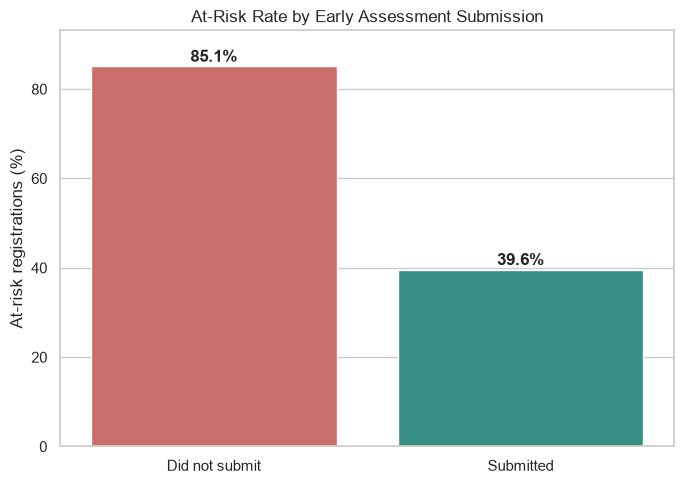

In [19]:
early_assessment_definitions = assessments[
    assessments["date"].between(0, 27, inclusive="both")
][
    [
        "code_module",
        "code_presentation",
        "id_assessment",
        "assessment_type",
        "date"
    ]
].copy()

early_submission_details = student_assessment.merge(
    early_assessment_definitions,
    on="id_assessment",
    how="inner",
    validate="many_to_one"
)

# Only information available by the end of day 27
early_submission_details = early_submission_details[
    early_submission_details["date_submitted"]
    .between(0, 27, inclusive="both")
].copy()

early_student_assessments = (
    early_submission_details
    .groupby(registration_keys)
    .agg(
        early_submissions=("id_assessment", "nunique"),
        early_mean_score=("score", "mean"),
        early_on_time_submissions=(
            "date_submitted",
            lambda x: 0
        )
    )
    .reset_index()
)

# Replace the temporary on-time column with a correct calculation
early_submission_details["submitted_on_time"] = (
    early_submission_details["date_submitted"]
    <= early_submission_details["date"]
).astype(int)

on_time_summary = (
    early_submission_details
    .groupby(registration_keys)["submitted_on_time"]
    .sum()
    .reset_index(name="early_on_time_submissions")
)

early_student_assessments = (
    early_student_assessments
    .drop(columns="early_on_time_submissions")
    .merge(
        on_time_summary,
        on=registration_keys,
        how="left",
        validate="one_to_one"
    )
)

eligible_presentations = assessment_opportunities[
    assessment_opportunities["early_assessments"] > 0
][
    ["code_module", "code_presentation"]
]

assessment_cohort = prediction_cohort.merge(
    eligible_presentations,
    on=["code_module", "code_presentation"],
    how="inner",
    validate="many_to_one"
)

assessment_cohort = assessment_cohort.merge(
    early_student_assessments,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

assessment_cohort["early_submissions"] = (
    assessment_cohort["early_submissions"]
    .fillna(0)
    .astype(int)
)

assessment_cohort["submitted_early_assessment"] = np.where(
    assessment_cohort["early_submissions"] > 0,
    "Submitted",
    "Did not submit"
)

submission_summary = (
    assessment_cohort
    .groupby("submitted_early_assessment")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

submission_summary["at_risk_rate"] *= 100

display(submission_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=submission_summary,
    x="submitted_early_assessment",
    y="at_risk_rate",
    hue="submitted_early_assessment",
    palette={
        "Submitted": "#2A9D8F",
        "Did not submit": "#D95F59"
    },
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Early Assessment Submission")
plt.xlabel("")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, submission_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

,early_score_band,registrations,at_risk_students,at_risk_rate,median_score
0,Below 40,1319,814,61.71,1.0
1,40-59,2144,1448,67.54,52.0
2,60-79,7429,3162,42.56,70.5
3,80 or above,8579,2285,26.63,89.0


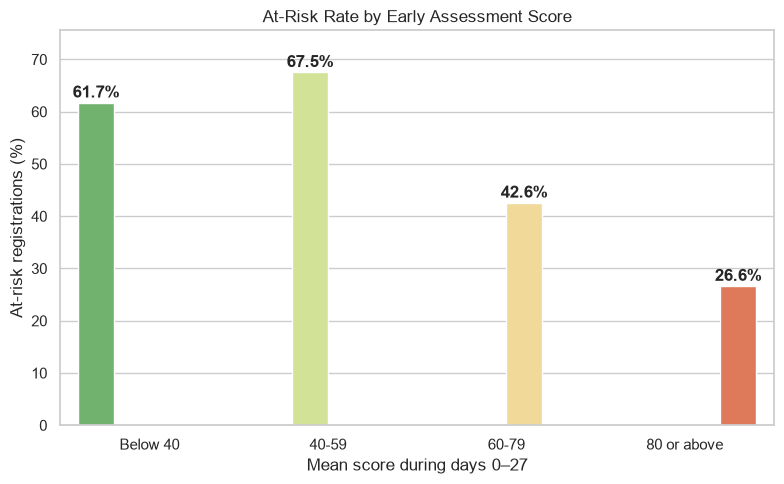

In [20]:
score_cohort = assessment_cohort[
    assessment_cohort["early_mean_score"].notna()
].copy()

score_cohort["early_score_band"] = pd.cut(
    score_cohort["early_mean_score"],
    bins=[-np.inf, 40, 60, 80, np.inf],
    right=False,
    labels=[
        "Below 40",
        "40-59",
        "60-79",
        "80 or above"
    ]
)

score_summary = (
    score_cohort
    .groupby("early_score_band", observed=True)
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean"),
        median_score=("early_mean_score", "median")
    )
    .reset_index()
)

score_summary["at_risk_rate"] *= 100

display(score_summary.round(2))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=score_summary,
    x="early_score_band",
    y="at_risk_rate",
    hue="early_score_band",
    palette="RdYlGn_r",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by Early Assessment Score")
plt.xlabel("Mean score during days 0–27")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, score_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

In [21]:
below_40_details = early_submission_details[
    early_submission_details["score"] < 40
].copy()

print("Number of below-40 submission records:",
      len(below_40_details))

print("\nMost common scores below 40:")
display(
    below_40_details["score"]
    .value_counts()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("submission_records")
)

print("\nBanked status among below-40 submissions:")
display(
    below_40_details["is_banked"]
    .value_counts(dropna=False)
    .to_frame("submission_records")
)

print("\nBelow-40 submissions by module:")
display(
    below_40_details["code_module"]
    .value_counts()
    .to_frame("submission_records")
)

Number of below-40 submission records: 1482

Most common scores below 40:


,submission_records
score,
1.0,692
30.0,140
33.0,91
0.0,86
20.0,83
22.0,52
10.0,50
37.0,47
11.0,32



Banked status among below-40 submissions:


,submission_records
is_banked,
0,1482



Below-40 submissions by module:


,submission_records
code_module,
BBB,743
CCC,417
DDD,263
FFF,51
AAA,8


In [22]:
score_one_details = early_submission_details[
    early_submission_details["score"] == 1
].copy()

score_one_summary = (
    score_one_details
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_assessment",
            "assessment_type",
            "date"
        ]
    )
    .size()
    .reset_index(name="score_one_records")
    .sort_values("score_one_records", ascending=False)
)

print("Total score-one records:", len(score_one_details))

display(score_one_summary.head(20))

Total score-one records: 692


,code_module,code_presentation,id_assessment,assessment_type,date,score_one_records
0,BBB,2014J,15020,TMA,19.0,692


In [23]:
assessment_15020 = student_assessment[
    student_assessment["id_assessment"] == 15020
].copy()

print("Submission records:", len(assessment_15020))
print("Unique scores:", assessment_15020["score"].nunique())
print("Minimum score:", assessment_15020["score"].min())
print("Maximum score:", assessment_15020["score"].max())

print("\nScore frequencies:")
display(
    assessment_15020["score"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("submission_records")
)

Submission records: 1776
Unique scores: 9
Minimum score: 0.0
Maximum score: 100.0

Score frequencies:


,submission_records
score,
0.0,15
1.0,717
50.0,1
60.0,1
75.0,4
80.0,9
85.0,1
90.0,2
100.0,1022


,early_score_band,registrations,at_risk_students,at_risk_rate,median_score
0,Below 40,648,587,90.59,30.0
1,40-59,2143,1447,67.52,52.0
2,60-79,7424,3160,42.56,70.5
3,80 or above,7616,1996,26.21,88.0


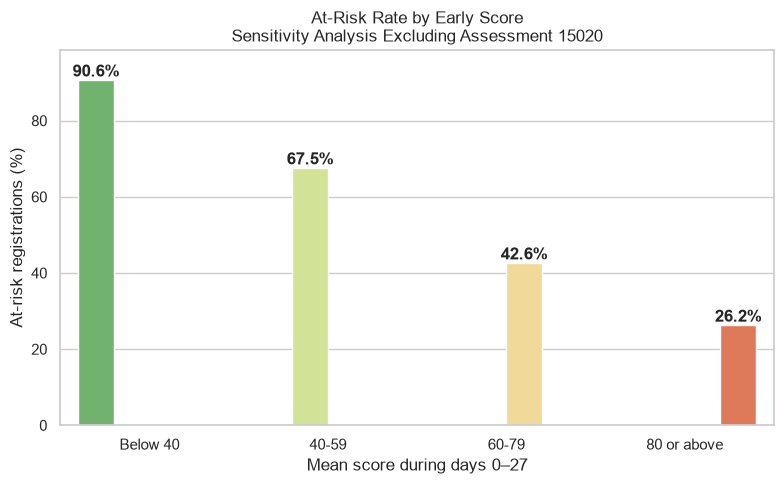

In [24]:
score_details_sensitivity = early_submission_details[
    early_submission_details["id_assessment"] != 15020
].copy()

student_scores_sensitivity = (
    score_details_sensitivity
    .groupby(registration_keys)
    .agg(
        early_mean_score=("score", "mean")
    )
    .reset_index()
)

score_cohort_sensitivity = prediction_cohort.merge(
    student_scores_sensitivity,
    on=registration_keys,
    how="inner",
    validate="one_to_one"
)

score_cohort_sensitivity["early_score_band"] = pd.cut(
    score_cohort_sensitivity["early_mean_score"],
    bins=[-np.inf, 40, 60, 80, np.inf],
    right=False,
    labels=[
        "Below 40",
        "40-59",
        "60-79",
        "80 or above"
    ]
)

score_summary_sensitivity = (
    score_cohort_sensitivity
    .groupby("early_score_band", observed=True)
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean"),
        median_score=("early_mean_score", "median")
    )
    .reset_index()
)

score_summary_sensitivity["at_risk_rate"] *= 100

display(score_summary_sensitivity.round(2))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=score_summary_sensitivity,
    x="early_score_band",
    y="at_risk_rate",
    hue="early_score_band",
    palette="RdYlGn_r",
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "At-Risk Rate by Early Score\n"
    "Sensitivity Analysis Excluding Assessment 15020"
)
plt.xlabel("Mean score during days 0–27")
plt.ylabel("At-risk registrations (%)")
plt.ylim(
    0,
    score_summary_sensitivity["at_risk_rate"].max() + 8
)
plt.tight_layout()
plt.show()

In [25]:
chunk_size = 500_000
daily_parts = []
chunks_processed = 0

columns_needed = [
    "code_module",
    "code_presentation",
    "id_student",
    "date",
    "sum_click"
]

for chunk in pd.read_csv(
    file_paths["studentVle.csv"],
    usecols=columns_needed,
    chunksize=chunk_size
):
    chunks_processed += 1

    early_chunk = chunk[
        chunk["date"].between(0, 27, inclusive="both")
    ].copy()

    daily_chunk = (
        early_chunk
        .groupby(
            registration_keys + ["date"],
            as_index=False
        )["sum_click"]
        .sum()
    )

    daily_parts.append(daily_chunk)

early_daily_activity = pd.concat(
    daily_parts,
    ignore_index=True
)

# Re-aggregate because one student-day may cross chunk boundaries
early_daily_activity = (
    early_daily_activity
    .groupby(
        registration_keys + ["date"],
        as_index=False
    )["sum_click"]
    .sum()
)

early_engagement = (
    early_daily_activity
    .groupby(registration_keys)
    .agg(
        total_clicks_28d=("sum_click", "sum"),
        active_days_28d=("date", "nunique"),
        average_clicks_active_day=("sum_click", "mean"),
        maximum_daily_clicks=("sum_click", "max"),
        first_active_day=("date", "min"),
        last_active_day=("date", "max")
    )
    .reset_index()
)

engagement_data = prediction_cohort.merge(
    early_engagement,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

engagement_columns = [
    "total_clicks_28d",
    "active_days_28d",
    "average_clicks_active_day",
    "maximum_daily_clicks"
]

engagement_data[engagement_columns] = (
    engagement_data[engagement_columns]
    .fillna(0)
)

engagement_data["no_activity_28d"] = (
    engagement_data["active_days_28d"] == 0
).astype(int)

print("Chunks processed:", chunks_processed)
print("Student-day records:", f"{len(early_daily_activity):,}")
print("Prediction-cohort registrations:", f"{len(engagement_data):,}")
print(
    "Registrations with no activity during days 0-27:",
    f"{engagement_data['no_activity_28d'].sum():,}"
)

display(early_engagement.head())

Chunks processed: 22
Student-day records: 301,723
Prediction-cohort registrations: 27,553
Registrations with no activity during days 0-27: 1,249


,code_module,code_presentation,id_student,total_clicks_28d,active_days_28d,average_clicks_active_day,maximum_daily_clicks,first_active_day,last_active_day
0,AAA,2013J,11391,303,7,43.285714,127,0,18
1,AAA,2013J,28400,335,11,30.454545,73,0,24
2,AAA,2013J,30268,179,6,29.833333,54,4,12
3,AAA,2013J,31604,309,16,19.312500,52,1,25
4,AAA,2013J,32885,272,16,17.000000,40,1,26


,activity_status,registrations,at_risk_students,at_risk_rate
0,No activity,1249,1017,81.43
1,Some activity,26304,11151,42.39


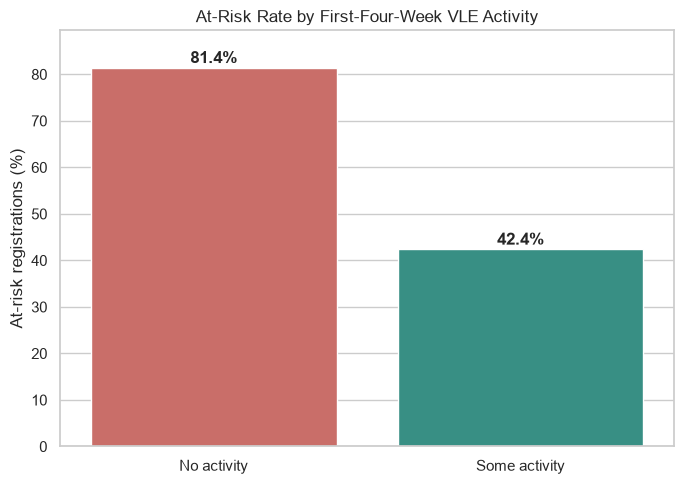

In [26]:
engagement_data["activity_status"] = np.where(
    engagement_data["no_activity_28d"] == 1,
    "No activity",
    "Some activity"
)

activity_status_summary = (
    engagement_data
    .groupby("activity_status")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reset_index()
)

activity_status_summary["at_risk_rate"] *= 100

display(activity_status_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=activity_status_summary,
    x="activity_status",
    y="at_risk_rate",
    hue="activity_status",
    palette={
        "No activity": "#D95F59",
        "Some activity": "#2A9D8F"
    },
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by First-Four-Week VLE Activity")
plt.xlabel("")
plt.ylabel("At-risk registrations (%)")
plt.ylim(
    0,
    activity_status_summary["at_risk_rate"].max() + 8
)
plt.tight_layout()
plt.show()

,registrations,median_total_clicks,median_active_days,median_clicks_per_active_day,median_maximum_daily_clicks
risk_label,,,,,
At risk,12168,119.0,7.0,16.14,42.0
Successful,15385,231.0,12.0,20.31,63.0


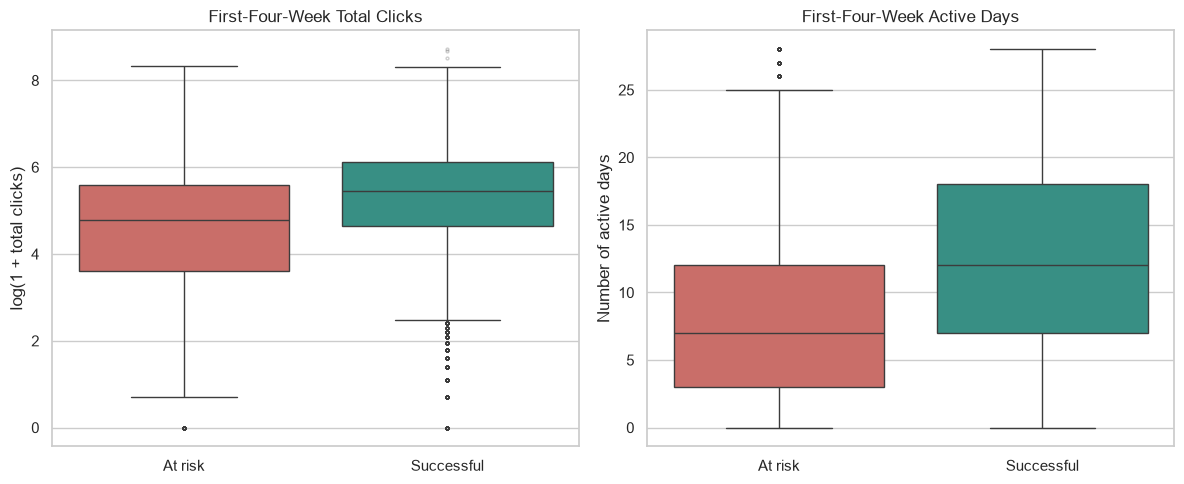

In [27]:
engagement_data["risk_label"] = (
    engagement_data["at_risk"]
    .map({0: "Successful", 1: "At risk"})
)

engagement_data["log_total_clicks"] = np.log1p(
    engagement_data["total_clicks_28d"]
)

engagement_by_outcome = (
    engagement_data
    .groupby("risk_label")
    .agg(
        registrations=("at_risk", "size"),
        median_total_clicks=("total_clicks_28d", "median"),
        median_active_days=("active_days_28d", "median"),
        median_clicks_per_active_day=(
            "average_clicks_active_day",
            "median"
        ),
        median_maximum_daily_clicks=(
            "maximum_daily_clicks",
            "median"
        )
    )
    .reindex(["At risk", "Successful"])
)

display(engagement_by_outcome.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=engagement_data,
    x="risk_label",
    y="log_total_clicks",
    order=["At risk", "Successful"],
    hue="risk_label",
    palette={
        "At risk": "#D95F59",
        "Successful": "#2A9D8F"
    },
    legend=False,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.25},
    ax=axes[0]
)

axes[0].set_title("First-Four-Week Total Clicks")
axes[0].set_xlabel("")
axes[0].set_ylabel("log(1 + total clicks)")

sns.boxplot(
    data=engagement_data,
    x="risk_label",
    y="active_days_28d",
    order=["At risk", "Successful"],
    hue="risk_label",
    palette={
        "At risk": "#D95F59",
        "Successful": "#2A9D8F"
    },
    legend=False,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.25},
    ax=axes[1]
)

axes[1].set_title("First-Four-Week Active Days")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of active days")

plt.tight_layout()
plt.show()

### Engagement gap within module presentations (Simpson's paradox check)

The engagement medians above pool all 22 module presentations. Modules differ in
how much online material they contain and in their at-risk rates, so the pooled
gap could partly reflect *which* modules at-risk students are enrolled in. This
check compares at-risk and successful students within each presentation, and
ranks every student against their own classmates.

,module_presentation,median_total_clicks_at_risk,median_total_clicks_successful,median_active_days_at_risk,median_active_days_successful,at_risk_rate,clicks_gap,active_days_gap
6,CCC_2014B,150.0,280.0,7.0,12.0,55.80,130.0,5.0
8,DDD_2013B,151.5,287.5,10.0,16.0,55.50,136.0,6.0
10,DDD_2014B,115.0,235.0,9.0,15.0,53.50,120.0,6.0
7,CCC_2014J,151.5,261.0,7.0,11.0,49.83,109.5,4.0
17,FFF_2014B,236.0,481.0,9.0,16.0,49.77,245.0,7.0
9,DDD_2013J,111.0,214.0,8.0,14.0,49.70,103.0,6.0
2,BBB_2013B,81.0,174.0,6.0,11.0,47.55,93.0,5.0
15,FFF_2013B,298.0,532.0,11.0,17.0,46.22,234.0,6.0
11,DDD_2014J,93.0,178.5,8.0,14.0,45.86,85.5,6.0
16,FFF_2013J,252.0,500.0,10.0,16.0,44.78,248.0,6.0


Successful > at risk in median total clicks: 22 of 22
Successful > at risk in median active days: 22 of 22

Median within-presentation percentile rank:


,total_clicks_28d_pct_in_presentation,active_days_28d_pct_in_presentation
risk_label,,
At risk,0.35,0.35
Successful,0.61,0.61


Spearman correlation between presentation median clicks and presentation at-risk rate: 0.0


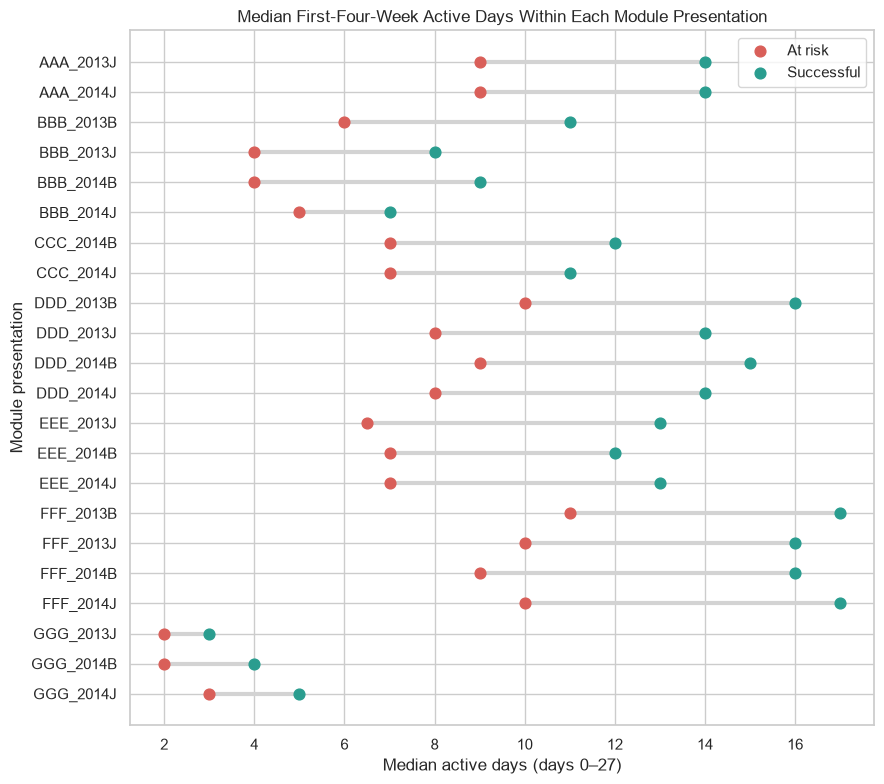

In [28]:
# ---- Simpson's paradox check: is the engagement gap present
# ---- within each module presentation, or only when they are pooled?

# 1. Median engagement by outcome inside each module presentation
within_presentation = (
    engagement_data
    .groupby(["module_presentation", "risk_label"])
    .agg(
        median_total_clicks=("total_clicks_28d", "median"),
        median_active_days=("active_days_28d", "median")
    )
    .unstack("risk_label")
)

within_presentation.columns = [
    f"{metric}_{label.lower().replace(' ', '_')}"
    for metric, label in within_presentation.columns
]

within_presentation = within_presentation.reset_index().merge(
    presentation_summary[["module_presentation", "at_risk_rate"]],
    on="module_presentation",
    how="left",
    validate="one_to_one"
)

within_presentation["clicks_gap"] = (
    within_presentation["median_total_clicks_successful"]
    - within_presentation["median_total_clicks_at_risk"]
)

within_presentation["active_days_gap"] = (
    within_presentation["median_active_days_successful"]
    - within_presentation["median_active_days_at_risk"]
)

display(
    within_presentation
    .sort_values("at_risk_rate", ascending=False)
    .round(2)
)

n_presentations = len(within_presentation)
print(
    "Successful > at risk in median total clicks:",
    (within_presentation["clicks_gap"] > 0).sum(), "of", n_presentations
)
print(
    "Successful > at risk in median active days:",
    (within_presentation["active_days_gap"] > 0).sum(), "of", n_presentations
)

# 2. Compare each student with their own classmates
#    (percentile rank within the module presentation, 0 = least, 1 = most active)
for column in ["total_clicks_28d", "active_days_28d"]:
    engagement_data[f"{column}_pct_in_presentation"] = (
        engagement_data
        .groupby("module_presentation")[column]
        .rank(pct=True)
    )

percentile_summary = (
    engagement_data
    .groupby("risk_label")[
        [
            "total_clicks_28d_pct_in_presentation",
            "active_days_28d_pct_in_presentation"
        ]
    ]
    .median()
    .reindex(["At risk", "Successful"])
)

print("\nMedian within-presentation percentile rank:")
display(percentile_summary.round(2))

# 3. Are low-engagement presentations also high-risk presentations?
presentation_engagement = (
    engagement_data
    .groupby("module_presentation")
    .agg(
        median_total_clicks=("total_clicks_28d", "median"),
        at_risk_rate=("at_risk", "mean")
    )
)

print(
    "Spearman correlation between presentation median clicks "
    "and presentation at-risk rate:",
    round(
        presentation_engagement["median_total_clicks"]
        .corr(presentation_engagement["at_risk_rate"], method="spearman"),
        2
    )
)

# 4. Plot: median active days for each outcome group in every presentation
plot_data = within_presentation.sort_values("module_presentation", ascending=False)
y_positions = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(9, 8))

ax.hlines(
    y=y_positions,
    xmin=plot_data["median_active_days_at_risk"],
    xmax=plot_data["median_active_days_successful"],
    color="lightgrey",
    linewidth=3,
    zorder=1
)

ax.scatter(
    plot_data["median_active_days_at_risk"],
    y_positions,
    color="#D95F59",
    s=60,
    label="At risk",
    zorder=2
)

ax.scatter(
    plot_data["median_active_days_successful"],
    y_positions,
    color="#2A9D8F",
    s=60,
    label="Successful",
    zorder=2
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["module_presentation"])
ax.set_title("Median First-Four-Week Active Days Within Each Module Presentation")
ax.set_xlabel("Median active days (days 0–27)")
ax.set_ylabel("Module presentation")
ax.legend()
plt.tight_layout()
plt.show()

,risk_label,week,median_clicks,mean_clicks,active_rate
0,At risk,1,18.0,49.59,74.00
1,At risk,2,15.0,43.73,71.41
2,At risk,3,28.0,62.40,75.39
3,At risk,4,12.0,41.04,68.67
4,Successful,1,49.0,87.49,87.15
5,Successful,2,44.0,79.32,87.73
6,Successful,3,60.0,97.43,90.15
7,Successful,4,37.0,74.55,86.42


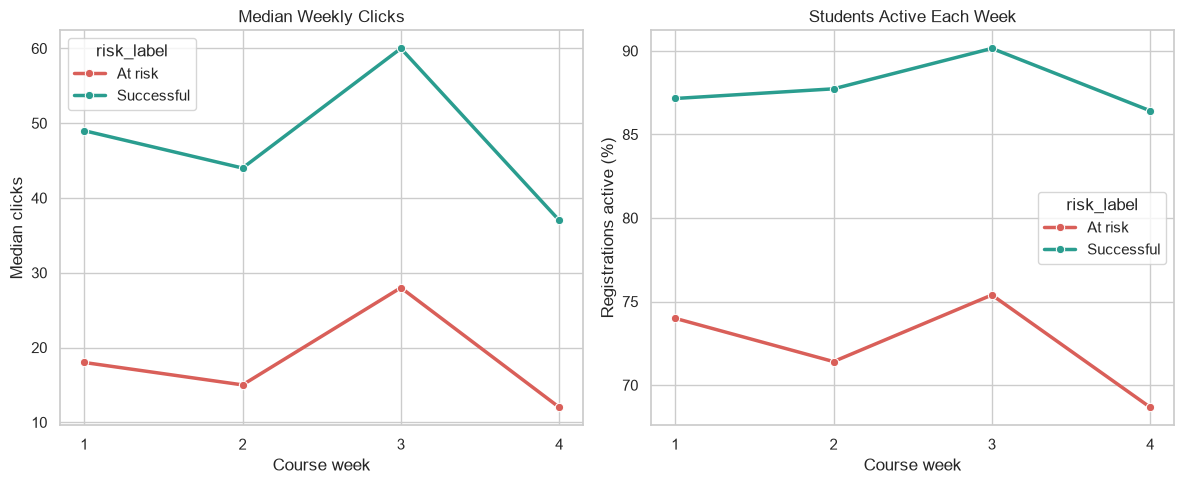

In [29]:
weekly_clicks = early_daily_activity.copy()

weekly_clicks["week"] = (
    weekly_clicks["date"] // 7 + 1
).astype(int)

weekly_clicks = (
    weekly_clicks
    .groupby(
        registration_keys + ["week"],
        as_index=False
    )["sum_click"]
    .sum()
)

cohort_keys = engagement_data[
    registration_keys + ["at_risk", "risk_label"]
].copy()

week_numbers = pd.DataFrame({
    "week": [1, 2, 3, 4]
})

student_week_grid = cohort_keys.merge(
    week_numbers,
    how="cross"
)

student_week_activity = student_week_grid.merge(
    weekly_clicks,
    on=registration_keys + ["week"],
    how="left",
    validate="one_to_one"
)

student_week_activity["sum_click"] = (
    student_week_activity["sum_click"]
    .fillna(0)
)

weekly_summary = (
    student_week_activity
    .groupby(["risk_label", "week"])
    .agg(
        median_clicks=("sum_click", "median"),
        mean_clicks=("sum_click", "mean"),
        active_rate=(
            "sum_click",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

display(weekly_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(
    data=weekly_summary,
    x="week",
    y="median_clicks",
    hue="risk_label",
    hue_order=["At risk", "Successful"],
    palette={
        "At risk": "#D95F59",
        "Successful": "#2A9D8F"
    },
    marker="o",
    linewidth=2.5,
    ax=axes[0]
)

axes[0].set_title("Median Weekly Clicks")
axes[0].set_xlabel("Course week")
axes[0].set_ylabel("Median clicks")
axes[0].set_xticks([1, 2, 3, 4])

sns.lineplot(
    data=weekly_summary,
    x="week",
    y="active_rate",
    hue="risk_label",
    hue_order=["At risk", "Successful"],
    palette={
        "At risk": "#D95F59",
        "Successful": "#2A9D8F"
    },
    marker="o",
    linewidth=2.5,
    ax=axes[1]
)

axes[1].set_title("Students Active Each Week")
axes[1].set_xlabel("Course week")
axes[1].set_ylabel("Registrations active (%)")
axes[1].set_xticks([1, 2, 3, 4])

plt.tight_layout()
plt.show()

,engagement_trend,registrations,at_risk_students,at_risk_rate
0,No activity,1249,1017,81.43
1,Decreased,11736,4878,41.56
2,Stable,2056,722,35.12
3,Increased,12512,5551,44.37


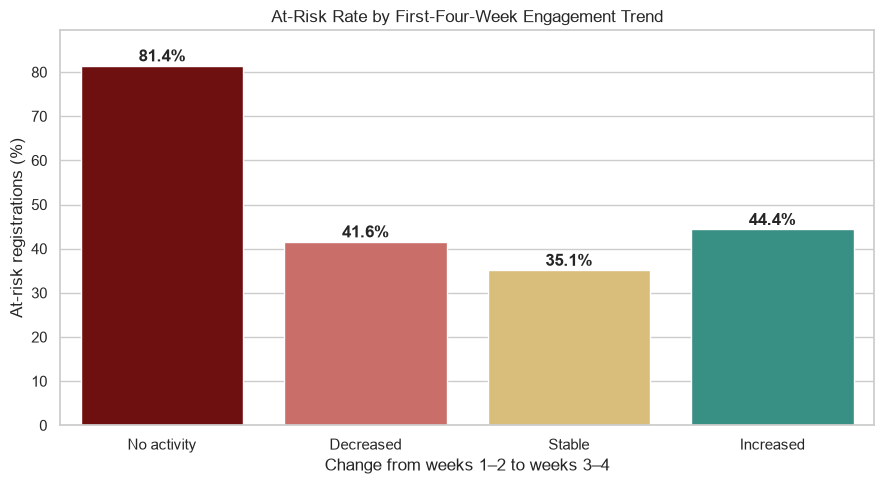

In [30]:
student_week_pivot = (
    student_week_activity
    .pivot_table(
        index=registration_keys + ["at_risk", "risk_label"],
        columns="week",
        values="sum_click",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

student_week_pivot["first_half_clicks"] = (
    student_week_pivot[1] + student_week_pivot[2]
)

student_week_pivot["second_half_clicks"] = (
    student_week_pivot[3] + student_week_pivot[4]
)

conditions = [
    (
        student_week_pivot["first_half_clicks"] == 0
    )
    & (
        student_week_pivot["second_half_clicks"] == 0
    ),
    student_week_pivot["second_half_clicks"]
    > student_week_pivot["first_half_clicks"] * 1.10,
    student_week_pivot["second_half_clicks"]
    < student_week_pivot["first_half_clicks"] * 0.90
]

choices = [
    "No activity",
    "Increased",
    "Decreased"
]

student_week_pivot["engagement_trend"] = np.select(
    conditions,
    choices,
    default="Stable"
)

trend_order = [
    "No activity",
    "Decreased",
    "Stable",
    "Increased"
]

trend_summary = (
    student_week_pivot
    .groupby("engagement_trend")
    .agg(
        registrations=("at_risk", "size"),
        at_risk_students=("at_risk", "sum"),
        at_risk_rate=("at_risk", "mean")
    )
    .reindex(trend_order)
    .reset_index()
)

trend_summary["at_risk_rate"] *= 100

display(trend_summary.round(2))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=trend_summary,
    x="engagement_trend",
    y="at_risk_rate",
    hue="engagement_trend",
    palette={
        "No activity": "#7F0000",
        "Decreased": "#D95F59",
        "Stable": "#E9C46A",
        "Increased": "#2A9D8F"
    },
    legend=False
)

for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title("At-Risk Rate by First-Four-Week Engagement Trend")
plt.xlabel("Change from weeks 1–2 to weeks 3–4")
plt.ylabel("At-risk registrations (%)")
plt.ylim(0, trend_summary["at_risk_rate"].max() + 8)
plt.tight_layout()
plt.show()

In [31]:
hypotheses = pd.DataFrame([
    {
        "ID": "H1",
        "Area": "VLE engagement",
        "Hypothesis": (
            "Students with more consistent first-four-week "
            "engagement will have a lower probability of being at risk."
        ),
        "EDA evidence": (
            "Successful students had median 231 clicks and 12 active "
            "days, compared with 119 clicks and 7 active days for "
            "at-risk students."
        )
    },
    {
        "ID": "H2",
        "Area": "No early activity",
        "Hypothesis": (
            "Students with no VLE activity during days 0-27 will have "
            "a higher probability of later failure or withdrawal."
        ),
        "EDA evidence": (
            "The at-risk rate was 81.4% with no activity, compared "
            "with 42.4% with some activity."
        )
    },
    {
        "ID": "H3",
        "Area": "Assessment participation",
        "Hypothesis": (
            "Students who do not submit an available early assessment "
            "will have a higher probability of being at risk."
        ),
        "EDA evidence": (
            "The at-risk rate was 85.1% for non-submitters and "
            "39.6% for submitters."
        )
    },
    {
        "ID": "H4",
        "Area": "Assessment performance",
        "Hypothesis": (
            "Higher early assessment scores will be associated with "
            "a lower probability of being at risk."
        ),
        "EDA evidence": (
            "After excluding anomalous assessment 15020, risk declined "
            "from 90.6% below score 40 to 26.2% at score 80 or above."
        )
    },
    {
        "ID": "H5",
        "Area": "Previous attempts",
        "Hypothesis": (
            "Students with more previous attempts will have a higher "
            "probability of being at risk."
        ),
        "EDA evidence": (
            "Risk increased from 41.8% with no previous attempts to "
            "66.2% with two or more attempts."
        )
    },
    {
        "ID": "H6",
        "Area": "Study load",
        "Hypothesis": (
            "Students studying more credits will have a higher "
            "probability of being at risk."
        ),
        "EDA evidence": (
            "Risk increased from 41.8% for up to 60 credits to "
            "61.1% for more than 180 credits."
        )
    },
    {
        "ID": "H7",
        "Area": "Module context",
        "Hypothesis": (
            "At-risk rates and predictive relationships will differ "
            "between modules and presentations."
        ),
        "EDA evidence": (
            "Module risk ranged from 26.0% for AAA to 52.4% for CCC, "
            "with further variation between presentations."
        )
    },
    {
        "ID": "H8",
        "Area": "Demographic fairness",
        "Hypothesis": (
            "Model performance may differ across demographic and "
            "socioeconomic groups and should be evaluated separately."
        ),
        "EDA evidence": (
            "Risk varied by disability, age, education, gender, and "
            "area-deprivation band. These are associations, not causal "
            "conclusions."
        )
    }
])

pd.set_option("display.max_colwidth", None)

display(hypotheses)

,ID,Area,Hypothesis,EDA evidence
0,H1,VLE engagement,Students with more consistent first-four-week engagement will have a lower probability of being at risk.,"Successful students had median 231 clicks and 12 active days, compared with 119 clicks and 7 active days for at-risk students."
1,H2,No early activity,Students with no VLE activity during days 0-27 will have a higher probability of later failure or withdrawal.,"The at-risk rate was 81.4% with no activity, compared with 42.4% with some activity."
2,H3,Assessment participation,Students who do not submit an available early assessment will have a higher probability of being at risk.,The at-risk rate was 85.1% for non-submitters and 39.6% for submitters.
3,H4,Assessment performance,Higher early assessment scores will be associated with a lower probability of being at risk.,"After excluding anomalous assessment 15020, risk declined from 90.6% below score 40 to 26.2% at score 80 or above."
4,H5,Previous attempts,Students with more previous attempts will have a higher probability of being at risk.,Risk increased from 41.8% with no previous attempts to 66.2% with two or more attempts.
5,H6,Study load,Students studying more credits will have a higher probability of being at risk.,Risk increased from 41.8% for up to 60 credits to 61.1% for more than 180 credits.
6,H7,Module context,At-risk rates and predictive relationships will differ between modules and presentations.,"Module risk ranged from 26.0% for AAA to 52.4% for CCC, with further variation between presentations."
7,H8,Demographic fairness,Model performance may differ across demographic and socioeconomic groups and should be evaluated separately.,"Risk varied by disability, age, education, gender, and area-deprivation band. These are associations, not causal conclusions."


In [32]:
from pathlib import Path

output_folder = Path("Outputs")
output_folder.mkdir(exist_ok=True)

# Correct the wording used in H4
hypotheses.loc[
    hypotheses["ID"] == "H4",
    "EDA evidence"
] = (
    "After excluding the unusual near-binary assessment 15020, "
    "risk declined from 90.6% below score 40 to 26.2% at "
    "score 80 or above."
)

base_columns = [
    "code_module",
    "code_presentation",
    "id_student",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability",
    "at_risk"
]

eda_handoff = prediction_cohort[base_columns].copy()

# Add early VLE engagement features
eda_handoff = eda_handoff.merge(
    early_engagement,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

engagement_features = [
    "total_clicks_28d",
    "active_days_28d",
    "average_clicks_active_day",
    "maximum_daily_clicks"
]

eda_handoff[engagement_features] = (
    eda_handoff[engagement_features]
    .fillna(0)
)

eda_handoff["no_activity_28d"] = (
    eda_handoff["active_days_28d"] == 0
).astype(int)
# Add engagement relative to classmates in the same module presentation
# (0 = least active, 1 = most active). Click levels differ widely between
# modules, so a rank within the presentation is comparable across modules.
for column in ["total_clicks_28d", "active_days_28d"]:
    eda_handoff[f"{column}_pct_in_presentation"] = (
        eda_handoff
        .groupby(["code_module", "code_presentation"])[column]
        .rank(pct=True)
    )
# Add engagement-timing features (built in In [30])
timing_features = student_week_pivot[
    registration_keys
    + [1, 2, 3, 4, "first_half_clicks", "second_half_clicks", "engagement_trend"]
].rename(columns={
    1: "week1_clicks",
    2: "week2_clicks",
    3: "week3_clicks",
    4: "week4_clicks"
})

for week in [1, 2, 3, 4]:
    timing_features[f"week{week}_active"] = (
        timing_features[f"week{week}_clicks"] > 0
    ).astype(int)

timing_features["engagement_change_clicks"] = (
    timing_features["second_half_clicks"]
    - timing_features["first_half_clicks"]
)

eda_handoff = eda_handoff.merge(
    timing_features,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

# Add module context: course length and presentation period
course_features = courses[
    ["code_module", "code_presentation", "module_presentation_length"]
].copy()

# B = presentation starting in February, J = presentation starting in October
course_features["presentation_period"] = (
    course_features["code_presentation"].str[-1]
)

eda_handoff = eda_handoff.merge(
    course_features,
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)
# Add assessment-opportunity indicator
opportunity_data = assessment_opportunities[
    [
        "code_module",
        "code_presentation",
        "early_assessments"
    ]
].copy()

opportunity_data["has_early_assessment_opportunity"] = (
    opportunity_data["early_assessments"] > 0
).astype(int)

eda_handoff = eda_handoff.merge(
    opportunity_data,
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)

# Add early submission behaviour
submission_features = early_student_assessments[
    registration_keys
    + [
        "early_submissions",
        "early_on_time_submissions"
    ]
].copy()

eda_handoff = eda_handoff.merge(
    submission_features,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

# Zero means no submission only when an opportunity existed
opportunity_mask = (
    eda_handoff["has_early_assessment_opportunity"] == 1
)

eda_handoff.loc[
    opportunity_mask,
    ["early_submissions", "early_on_time_submissions"]
] = (
    eda_handoff.loc[
        opportunity_mask,
        ["early_submissions", "early_on_time_submissions"]
    ]
    .fillna(0)
)

# Add cleaned early score
clean_score_features = (
    student_scores_sensitivity
    .rename(
        columns={
            "early_mean_score": "early_mean_score_clean"
        }
    )
)

eda_handoff = eda_handoff.merge(
    clean_score_features,
    on=registration_keys,
    how="left",
    validate="one_to_one"
)

# Final audit
audit_summary = pd.DataFrame({
    "check": [
        "Rows in prediction cohort",
        "Rows in EDA handoff",
        "Duplicate registration keys",
        "At-risk registrations",
        "Successful registrations",
        "Rows containing final_result",
        "Rows containing withdrawal date"
    ],
    "result": [
        len(prediction_cohort),
        len(eda_handoff),
        eda_handoff.duplicated(
            subset=registration_keys
        ).sum(),
        int(eda_handoff["at_risk"].sum()),
        int((eda_handoff["at_risk"] == 0).sum()),
        int("final_result" in eda_handoff.columns),
        int("date_unregistration" in eda_handoff.columns)
    ]
})

display(audit_summary)

# Save team handoff files
eda_handoff.to_csv(
    output_folder / "oulad_day27_eda_handoff.csv",
    index=False
)

hypotheses.to_csv(
    output_folder / "oulad_eda_hypotheses.csv",
    index=False
)

print("\nSaved files:")
print(output_folder / "oulad_day27_eda_handoff.csv")
print(output_folder / "oulad_eda_hypotheses.csv")

,check,result
0,Rows in prediction cohort,27553
1,Rows in EDA handoff,27553
2,Duplicate registration keys,0
3,At-risk registrations,12168
4,Successful registrations,15385
5,Rows containing final_result,0
6,Rows containing withdrawal date,0



Saved files:
Outputs\oulad_day27_eda_handoff.csv
Outputs\oulad_eda_hypotheses.csv


---
# Part 5 · Unified modelling table

The EDA produced its outputs as several separate pieces (`prediction_cohort`, `early_engagement`,
`student_week_pivot`, the assessment summaries, …). Before feature engineering, everything relevant is
combined into **one table in memory, `model_table`**: one row per registration
(`code_module + code_presentation + id_student`), every column known by the end of day 27, plus the target.
Nothing is written to disk.

Compared with the EDA handoff, the unified table also brings in information from source tables the EDA had
not used yet, all still available by day 27:

| Source table | Added to the unified table |
|---|---|
| `studentRegistration` | `date_registration` (registration date, *not* the withdrawal date) |
| `studentVle` (days **before** day 0) | pre-course activity: `pre_start_clicks`, `pre_start_active_days` |
| `studentVle` + `vle` | clicks by **type of resource** (forum, content, quiz, …) and number of distinct resources used |
| `studentVle` (daily) | `days_since_last_active` and the longest run of inactive days |
| `assessments` + `studentAssessment` | number of *scorable* early assessments, scored submissions, days submitted before the deadline |

Two data issues found in the EDA are applied here: assessment **15020** (BBB_2014J, weight 0, near-binary
scores) is excluded from score features, and assessment **25341** (DDD_2013B, implausible recorded deadline)
is excluded from the on-time count.

In [33]:
# ---- 5.1  One more pass over studentVle: pre-course activity and resource types ----
# The EDA kept only days 0-27. Clicks before the module starts (negative days) and
# the type of resource clicked are also known at day 27, so they are kept here.

activity_groups = {
    "forumng": "forum",
    "oucontent": "content", "page": "content", "htmlactivity": "content", "dualpane": "content",
    "homepage": "homepage",
    "quiz": "quiz", "externalquiz": "quiz", "questionnaire": "quiz",
    "subpage": "navigation", "sharedsubpage": "navigation",
    "resource": "resource", "url": "resource", "folder": "resource",
}
# Everything else (wikis, glossaries, live sessions, ...) is grouped as "collaboration"
site_groups = vle[["id_site", "activity_type"]].copy()
site_groups["activity_group"] = (
    site_groups["activity_type"].map(activity_groups).fillna("collaboration")
)

site_day_parts = []
for chunk in pd.read_csv(
    file_paths["studentVle.csv"],
    usecols=registration_keys + ["id_site", "date", "sum_click"],
    chunksize=500_000,
):
    chunk = chunk[chunk["date"] <= 27]          # nothing after the prediction point
    site_day_parts.append(
        chunk.groupby(registration_keys + ["id_site", "date"], as_index=False)["sum_click"].sum()
    )

site_day_activity = (
    pd.concat(site_day_parts, ignore_index=True)
    .groupby(registration_keys + ["id_site", "date"], as_index=False)["sum_click"].sum()
    .merge(site_groups[["id_site", "activity_group"]], on="id_site", how="left", validate="many_to_one")
    .merge(prediction_cohort[registration_keys], on=registration_keys, how="inner")  # cohort only
)

# Pre-course activity (days before the module start)
pre_start = site_day_activity[site_day_activity["date"] < 0]
pre_start_activity = (
    pre_start.groupby(registration_keys)
    .agg(pre_start_clicks=("sum_click", "sum"), pre_start_active_days=("date", "nunique"))
    .reset_index()
)

# Days 0-27: clicks by resource type and number of distinct resources
in_window = site_day_activity[site_day_activity["date"].between(0, 27)]
activity_mix = (
    in_window.pivot_table(index=registration_keys, columns="activity_group",
                          values="sum_click", aggfunc="sum", fill_value=0)
    .add_prefix("clicks_").add_suffix("_28d")
)
activity_mix.columns.name = None
activity_mix["distinct_resources_28d"] = in_window.groupby(registration_keys)["id_site"].nunique()
activity_mix = activity_mix.reset_index()

# Longest run of consecutive inactive days within days 0-27 (irregularity)
active_dates = (
    early_daily_activity[registration_keys + ["date"]]
    .drop_duplicates()
    .sort_values(registration_keys + ["date"])
)
active_dates["previous_date"] = (
    active_dates.groupby(registration_keys)["date"].shift(fill_value=-1)
)
active_dates["gap_before"] = active_dates["date"] - active_dates["previous_date"] - 1
inactivity_runs = active_dates.groupby(registration_keys).agg(
    longest_gap_inside=("gap_before", "max"), last_date=("date", "max")
)
inactivity_runs["longest_inactive_run_28d"] = np.maximum(
    inactivity_runs["longest_gap_inside"], 27 - inactivity_runs["last_date"]
)
inactivity_runs = inactivity_runs[["longest_inactive_run_28d"]].reset_index()

print(f"student-resource-day records up to day 27: {len(site_day_activity):,}")
print(f"registrations with pre-course activity:     {len(pre_start_activity):,}")
print(f"registrations with activity in days 0-27:   {len(activity_mix):,}")
display(
    in_window.groupby("activity_group")["sum_click"].sum()
    .sort_values(ascending=False).to_frame("clicks_days_0_27")
)

student-resource-day records up to day 27: 2,199,933
registrations with pre-course activity:     22,077
registrations with activity in days 0-27:   26,304


,clicks_days_0_27
activity_group,
forum,2088922
content,1578242
homepage,1399615
quiz,1196308
navigation,754457
resource,378001
collaboration,210971


In [34]:
# ---- 5.2  Early assessment information, with the two EDA corrections applied ----
UNSCORABLE_ASSESSMENTS = [15020]       # near-binary practice TMA (weight 0) in BBB_2014J
UNRELIABLE_DEADLINES = [25341]         # recorded deadline implausible (DDD_2013B)

# Presentation level: what was due by day 27
early_due = assessments[assessments["date"].between(0, 27)].copy()
early_due["scorable"] = ~early_due["id_assessment"].isin(UNSCORABLE_ASSESSMENTS)
assessment_context = (
    courses[["code_module", "code_presentation"]]
    .merge(
        early_due.groupby(["code_module", "code_presentation"]).agg(
            early_assessments=("id_assessment", "nunique"),
            early_scorable_assessments=("scorable", "sum"),
            first_early_deadline=("date", "min"),
        ).reset_index(),
        on=["code_module", "code_presentation"], how="left", validate="one_to_one",
    )
)
assessment_context[["early_assessments", "early_scorable_assessments"]] = (
    assessment_context[["early_assessments", "early_scorable_assessments"]].fillna(0).astype(int)
)
assessment_context["has_early_assessment_opportunity"] = (
    assessment_context["early_assessments"] > 0
).astype(int)

# Registration level: submissions made by day 27 (early_submission_details from the EDA)
submissions = early_submission_details.copy()
submissions["reliable_deadline"] = ~submissions["id_assessment"].isin(UNRELIABLE_DEADLINES)
submissions["on_time"] = (
    (submissions["date_submitted"] <= submissions["date"]) & submissions["reliable_deadline"]
).astype(int)
submissions["days_before_deadline"] = (
    (submissions["date"] - submissions["date_submitted"]).where(submissions["reliable_deadline"])
)
submissions["clean_score"] = submissions["score"].where(
    ~submissions["id_assessment"].isin(UNSCORABLE_ASSESSMENTS)
)

student_early_assessment = (
    submissions.groupby(registration_keys)
    .agg(
        early_submissions=("id_assessment", "nunique"),
        early_on_time_submissions=("on_time", "sum"),
        early_scored_submissions=("clean_score", "count"),
        early_mean_score_clean=("clean_score", "mean"),
        early_mean_days_before_deadline=("days_before_deadline", "mean"),
    )
    .reset_index()
)

display(
    assessment_context.query("early_assessments > 0")
    .sort_values(["code_module", "code_presentation"])
    .reset_index(drop=True)
)

,code_module,code_presentation,early_assessments,early_scorable_assessments,first_early_deadline,has_early_assessment_opportunity
0,AAA,2013J,1,1,19.0,1
1,AAA,2014J,1,1,19.0,1
2,BBB,2013B,1,1,19.0,1
3,BBB,2013J,1,1,19.0,1
4,BBB,2014B,1,1,12.0,1
5,BBB,2014J,1,0,19.0,1
6,CCC,2014B,1,1,18.0,1
7,CCC,2014J,1,1,18.0,1
8,DDD,2013B,2,2,23.0,1
9,DDD,2013J,1,1,25.0,1


In [35]:
# ---- 5.3  Build the unified modelling table: one row per registration ----
presentation_keys = ["code_module", "code_presentation"]

background_columns = [
    "gender", "region", "highest_education", "imd_band", "age_band", "disability",
    "num_of_prev_attempts", "studied_credits",
]

model_table = (
    # cohort and target (from the EDA), original labels from studentInfo
    prediction_cohort[registration_keys + ["at_risk"]]
    .merge(student_info[registration_keys + background_columns],
           on=registration_keys, how="left", validate="one_to_one")
    .merge(student_registration[registration_keys + ["date_registration"]],
           on=registration_keys, how="left", validate="one_to_one")
    # module context
    .merge(courses, on=presentation_keys, how="left", validate="many_to_one")
    .merge(assessment_context, on=presentation_keys, how="left", validate="many_to_one")
    # VLE engagement, days 0-27 (EDA)
    .merge(early_engagement, on=registration_keys, how="left", validate="one_to_one")
    .merge(
        student_week_pivot[registration_keys + [1, 2, 3, 4, "first_half_clicks",
                                                "second_half_clicks", "engagement_trend"]]
        .rename(columns={w: f"week{w}_clicks" for w in [1, 2, 3, 4]}),
        on=registration_keys, how="left", validate="one_to_one",
    )
    # new VLE information
    .merge(activity_mix, on=registration_keys, how="left", validate="one_to_one")
    .merge(inactivity_runs, on=registration_keys, how="left", validate="one_to_one")
    .merge(pre_start_activity, on=registration_keys, how="left", validate="one_to_one")
    # early assessment behaviour
    .merge(student_early_assessment, on=registration_keys, how="left", validate="one_to_one")
)

model_table["module_presentation"] = (
    model_table["code_module"] + "_" + model_table["code_presentation"]
)
model_table["presentation_period"] = model_table["code_presentation"].str[-1]
model_table["imd_band"] = model_table["imd_band"].replace({"10-20": "10-20%"})

# --- Fill rules: zero only where zero is the true value ---
click_count_columns = (
    ["total_clicks_28d", "active_days_28d", "average_clicks_active_day", "maximum_daily_clicks",
     "pre_start_clicks", "pre_start_active_days", "distinct_resources_28d"]
    + [c for c in model_table.columns if c.startswith("clicks_") and c.endswith("_28d")]
)
model_table[click_count_columns] = model_table[click_count_columns].fillna(0)
model_table["no_activity_28d"] = (model_table["active_days_28d"] == 0).astype(int)
model_table["longest_inactive_run_28d"] = model_table["longest_inactive_run_28d"].fillna(28)
model_table["days_since_last_active"] = 27 - model_table["last_active_day"]   # NaN = never active
for week in [1, 2, 3, 4]:
    model_table[f"week{week}_active"] = (model_table[f"week{week}_clicks"] > 0).astype(int)
model_table["engagement_change_clicks"] = (
    model_table["second_half_clicks"] - model_table["first_half_clicks"]
)

# Assessment counts: 0 = due but not submitted; NaN = nothing was due (EEE, GGG)
opportunity = model_table["has_early_assessment_opportunity"] == 1
count_columns = ["early_submissions", "early_on_time_submissions", "early_scored_submissions"]
model_table.loc[opportunity, count_columns] = model_table.loc[opportunity, count_columns].fillna(0)
model_table.loc[~opportunity, count_columns] = np.nan

# Column order: identifiers, target, then by source
column_order = (
    registration_keys + ["module_presentation", "at_risk"]
    + background_columns + ["date_registration"]
    + ["module_presentation_length", "presentation_period", "early_assessments",
       "early_scorable_assessments", "has_early_assessment_opportunity", "first_early_deadline"]
    + ["total_clicks_28d", "active_days_28d", "average_clicks_active_day", "maximum_daily_clicks",
       "first_active_day", "last_active_day", "days_since_last_active", "no_activity_28d",
       "longest_inactive_run_28d", "distinct_resources_28d"]
    + sorted(c for c in model_table.columns if c.startswith("clicks_"))
    + [f"week{w}_clicks" for w in [1, 2, 3, 4]] + [f"week{w}_active" for w in [1, 2, 3, 4]]
    + ["first_half_clicks", "second_half_clicks", "engagement_change_clicks", "engagement_trend"]
    + ["pre_start_clicks", "pre_start_active_days"]
    + ["early_submissions", "early_on_time_submissions", "early_scored_submissions",
       "early_mean_score_clean", "early_mean_days_before_deadline"]
)
model_table = model_table[column_order]

print(f"model_table: {model_table.shape[0]:,} rows x {model_table.shape[1]} columns")
display(model_table.head())

model_table: 27,553 rows x 56 columns


,code_module,code_presentation,id_student,module_presentation,at_risk,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,date_registration,module_presentation_length,presentation_period,early_assessments,early_scorable_assessments,has_early_assessment_opportunity,first_early_deadline,total_clicks_28d,active_days_28d,average_clicks_active_day,maximum_daily_clicks,first_active_day,last_active_day,days_since_last_active,no_activity_28d,longest_inactive_run_28d,distinct_resources_28d,clicks_collaboration_28d,clicks_content_28d,clicks_forum_28d,clicks_homepage_28d,clicks_navigation_28d,clicks_quiz_28d,clicks_resource_28d,week1_clicks,week2_clicks,week3_clicks,week4_clicks,week1_active,week2_active,week3_active,week4_active,first_half_clicks,second_half_clicks,engagement_change_clicks,engagement_trend,pre_start_clicks,pre_start_active_days,early_submissions,early_on_time_submissions,early_scored_submissions,early_mean_score_clean,early_mean_days_before_deadline
0,AAA,2013J,11391,AAA_2013J,0,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240,-159.0,268,J,1,1,1,19.0,303.0,7.0,43.285714,127.0,0.0,18.0,9.0,0,9.0,24.0,0.0,195.0,53.0,35.0,10.0,0.0,10.0,183.0,20.0,100.0,0.0,1,1,1,0,203.0,100.0,-103.0,Decreased,98.0,1.0,1.0,1.0,1.0,78.0,1.0
1,AAA,2013J,28400,AAA_2013J,0,F,Scotland,HE Qualification,20-30%,35-55,N,0,60,-53.0,268,J,1,1,1,19.0,335.0,11.0,30.454545,73.0,0.0,24.0,3.0,0,7.0,21.0,0.0,77.0,131.0,75.0,32.0,0.0,20.0,175.0,66.0,37.0,57.0,1,1,1,1,241.0,94.0,-147.0,Decreased,215.0,7.0,1.0,0.0,1.0,70.0,-3.0
2,AAA,2013J,31604,AAA_2013J,0,F,South East Region,A Level or Equivalent,50-60%,35-55,N,0,60,-52.0,268,J,1,1,1,19.0,309.0,16.0,19.312500,52.0,1.0,25.0,2.0,0,5.0,21.0,0.0,97.0,102.0,64.0,31.0,0.0,15.0,22.0,154.0,108.0,25.0,1,1,1,1,176.0,133.0,-43.0,Decreased,169.0,5.0,1.0,1.0,1.0,72.0,2.0
3,AAA,2013J,32885,AAA_2013J,0,F,West Midlands Region,Lower Than A Level,50-60%,0-35,N,0,60,-176.0,268,J,1,1,1,19.0,272.0,16.0,17.000000,40.0,1.0,26.0,1.0,0,4.0,18.0,0.0,143.0,65.0,50.0,11.0,0.0,3.0,61.0,116.0,37.0,58.0,1,1,1,1,177.0,95.0,-82.0,Decreased,295.0,8.0,1.0,0.0,1.0,69.0,-7.0
4,AAA,2013J,38053,AAA_2013J,0,M,Wales,A Level or Equivalent,80-90%,35-55,N,0,60,-110.0,268,J,1,1,1,19.0,450.0,23.0,19.565217,73.0,0.0,25.0,2.0,0,2.0,20.0,0.0,86.0,219.0,119.0,16.0,0.0,10.0,135.0,141.0,135.0,39.0,1,1,1,1,276.0,174.0,-102.0,Decreased,277.0,9.0,1.0,1.0,1.0,79.0,0.0


In [36]:
# ---- 5.4  Audit the unified table ----
forbidden = {"final_result", "date_unregistration"}
audit = pd.DataFrame({
    "check": [
        "Rows (should equal the prediction cohort)",
        "Duplicate registration keys",
        "At-risk registrations",
        "Successful registrations",
        "Leakage columns present (final_result, date_unregistration)",
        "Latest VLE day used",
        "Latest assessment submission day used",
    ],
    "result": [
        f"{len(model_table):,} / {len(prediction_cohort):,}",
        int(model_table.duplicated(subset=registration_keys).sum()),
        f"{int(model_table['at_risk'].sum()):,}",
        f"{int((model_table['at_risk'] == 0).sum()):,}",
        ", ".join(sorted(forbidden & set(model_table.columns))) or "none",
        int(site_day_activity["date"].max()),
        int(submissions["date_submitted"].max()),
    ],
})
display(audit)

# Consistency with the EDA handoff built above (same definitions -> same values)
shared = [c for c in eda_handoff.columns
          if c in model_table.columns and c not in registration_keys + ["age_band", "imd_band"]]
check = model_table[registration_keys + shared].merge(
    eda_handoff[registration_keys + shared], on=registration_keys, suffixes=("", "_eda")
)
mismatches = {
    c: int((~((check[c] == check[f"{c}_eda"]) | (check[c].isna() & check[f"{c}_eda"].isna()))).sum())
    for c in shared
}
print("Columns shared with the EDA handoff:", len(shared))
print("Columns that differ:", {c: n for c, n in mismatches.items() if n} or "none")
late_25341 = submissions.query("id_assessment == 25341 and date_submitted <= date")
print("Submissions to 25341 that would have counted as on time under its recorded deadline:",
      len(late_25341), "-> excluding it changes no cohort values, but protects against the bad deadline")

# Missing values: every gap has a documented meaning
missing = model_table.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["meaning"] = missing.index.map({
    "imd_band": "not recorded in OULAD (not a deprivation level)",
    "date_registration": "not recorded in OULAD",
    "first_early_deadline": "no assessment due by day 27 (EEE, GGG)",
    "first_active_day": "never active in days 0-27",
    "last_active_day": "never active in days 0-27",
    "days_since_last_active": "never active in days 0-27",
    "early_submissions": "no assessment due by day 27 (EEE, GGG)",
    "early_on_time_submissions": "no assessment due by day 27 (EEE, GGG)",
    "early_scored_submissions": "no assessment due by day 27 (EEE, GGG)",
    "early_mean_score_clean": "nothing due, nothing submitted, or only assessment 15020 submitted",
    "early_mean_days_before_deadline": "nothing due, nothing submitted, or only assessment 25341 submitted",
})
display(missing)

,check,result
0,Rows (should equal the prediction cohort),"27,553 / 27,553"
1,Duplicate registration keys,0
2,At-risk registrations,"12,168"
3,Successful registrations,"15,385"
4,"Leakage columns present (final_result, date_unregistration)",none
5,Latest VLE day used,27
6,Latest assessment submission day used,27


Columns shared with the EDA handoff: 33
Columns that differ: none
Submissions to 25341 that would have counted as on time under its recorded deadline: 0 -> excluding it changes no cohort values, but protects against the bad deadline


,missing,meaning
imd_band,1029,not recorded in OULAD (not a deprivation level)
date_registration,7,not recorded in OULAD
first_early_deadline,4991,"no assessment due by day 27 (EEE, GGG)"
first_active_day,1249,never active in days 0-27
last_active_day,1249,never active in days 0-27
days_since_last_active,1249,never active in days 0-27
early_submissions,4991,"no assessment due by day 27 (EEE, GGG)"
early_on_time_submissions,4991,"no assessment due by day 27 (EEE, GGG)"
early_scored_submissions,4991,"no assessment due by day 27 (EEE, GGG)"
early_mean_score_clean,9722,"nothing due, nothing submitted, or only assessment 15020 submitted"


**Column guide for `model_table`.** Identifiers (`code_module`, `code_presentation`, `id_student`,
`module_presentation`) are used for grouping and splitting only, never as features (except `code_module`,
which is module context). `at_risk` is the target.

| Group | Columns | Source |
|---|---|---|
| Background (known at enrolment) | `gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`, `num_of_prev_attempts`, `studied_credits`, `date_registration` | studentInfo, studentRegistration |
| Module context | `module_presentation_length`, `presentation_period`, `early_assessments`, `early_scorable_assessments`, `has_early_assessment_opportunity`, `first_early_deadline` | courses, assessments |
| VLE engagement, days 0–27 | `total_clicks_28d`, `active_days_28d`, `average_clicks_active_day`, `maximum_daily_clicks`, `first_active_day`, `last_active_day`, `days_since_last_active`, `no_activity_28d`, `longest_inactive_run_28d`, `distinct_resources_28d` | studentVle |
| Resource mix, days 0–27 | `clicks_forum_28d`, `clicks_content_28d`, `clicks_homepage_28d`, `clicks_quiz_28d`, `clicks_navigation_28d`, `clicks_resource_28d`, `clicks_collaboration_28d` | studentVle + vle |
| Engagement timing | `week1_clicks` … `week4_clicks`, `week1_active` … `week4_active`, `first_half_clicks`, `second_half_clicks`, `engagement_change_clicks`, `engagement_trend` | studentVle |
| Pre-course activity | `pre_start_clicks`, `pre_start_active_days` | studentVle (days < 0) |
| Early assessment | `early_submissions`, `early_on_time_submissions`, `early_scored_submissions`, `early_mean_score_clean`, `early_mean_days_before_deadline` | assessments + studentAssessment |

---
# Part 6 · Feature engineering

Three principles carried over from the EDA:

1. **Engagement relative to module context.** Click levels differ hugely between modules, so every engagement
   measure is also expressed *relative to classmates in the same presentation*: a percentile rank (0 = least
   active, 1 = most active) and, for the main volume measures, a z-score of log-clicks. These use only
   information that exists at day 27 (all classmates' activity up to day 27), never the target.
2. **Structural missingness is kept apart from zero.** "No assessment was due" stays missing; "due but not
   submitted" is 0.
3. **Nothing from after day 27.**

The temporal hold-out is fixed here, before any modelling: the **2014J presentations** (the latest in the
data) are the untouched test set. Statistics needed for feature construction (one fill value) come from the
earlier presentations only.

In [37]:
# ---- 6.1  Hold-out definition (fixed before any modelling) ----
TEST_PRESENTATIONS = ["2014J"]
is_test = model_table["code_presentation"].isin(TEST_PRESENTATIONS)

features = model_table.copy()

# ---- 6.2  Background features ----
education_order = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent",
                   "HE Qualification", "Post Graduate Qualification"]
imd_order = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%",
             "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
age_order = ["0-35", "35-55", "55<="]

features["education_level"] = features["highest_education"].map(
    {label: i for i, label in enumerate(education_order)})
features["imd_decile"] = features["imd_band"].map({label: i for i, label in enumerate(imd_order)})
features["imd_missing"] = features["imd_band"].isna().astype(int)
features["age_level"] = features["age_band"].map({label: i for i, label in enumerate(age_order)})
features["registered_days_before_start"] = -features["date_registration"]
features["log_studied_credits"] = np.log(features["studied_credits"])

# ---- 6.3  Absolute engagement features ----
week_cols = [f"week{w}_clicks" for w in [1, 2, 3, 4]]
features["log_total_clicks_28d"] = np.log1p(features["total_clicks_28d"])
features["log_pre_start_clicks"] = np.log1p(features["pre_start_clicks"])
features["active_weeks_28d"] = features[[f"week{w}_active" for w in [1, 2, 3, 4]]].sum(axis=1)
features["weekly_clicks_cv"] = (
    features[week_cols].std(axis=1, ddof=0) / features[week_cols].mean(axis=1)
).fillna(0)                                         # irregularity; 0 when never active
features["week4_share"] = (features["week4_clicks"] / features["total_clicks_28d"]).where(
    features["total_clicks_28d"] > 0)               # how much of the activity is recent
features["engagement_change_log"] = (
    np.log1p(features["second_half_clicks"]) - np.log1p(features["first_half_clicks"])
)                                                   # change without exploding percentages

activity_group_names = ["forum", "content", "homepage", "quiz", "navigation", "resource", "collaboration"]
for group in activity_group_names:
    features[f"share_{group}_28d"] = (
        features[f"clicks_{group}_28d"] / features["total_clicks_28d"]
    ).where(features["total_clicks_28d"] > 0)
features["activity_types_used_28d"] = (
    features[[f"clicks_{g}_28d" for g in activity_group_names]].gt(0).sum(axis=1)
)

# ---- 6.4  Early assessment features ----
features["early_submission_rate"] = features["early_submissions"] / features["early_assessments"]
features["early_on_time_rate"] = features["early_on_time_submissions"] / features["early_assessments"]

# Score: a student who submitted but has no valid score (almost only BBB_2014J, whose only
# early assessment is 15020) is NOT a non-submitter. Their score is set to a neutral value
# (median of scored submitters in the earlier presentations) instead of being left missing,
# because "missing score" means "did not submit" everywhere else.
submitted_without_score = (features["early_submissions"] > 0) & features["early_mean_score_clean"].isna()
neutral_score = features.loc[~is_test, "early_mean_score_clean"].median()
features["early_score"] = features["early_mean_score_clean"].where(
    ~submitted_without_score, neutral_score)
print(f"Submitted but no valid score: {submitted_without_score.sum():,} registrations "
      f"({submitted_without_score[is_test].sum():,} in the test presentations); "
      f"neutral score = {neutral_score:.1f}")

# ---- 6.5  Engagement relative to the module presentation ----
rank_sources = [
    "total_clicks_28d", "active_days_28d", "average_clicks_active_day", "maximum_daily_clicks",
    "week1_clicks", "week2_clicks", "week3_clicks", "week4_clicks",
    "distinct_resources_28d", "pre_start_clicks", "longest_inactive_run_28d",
    "clicks_forum_28d", "clicks_content_28d", "clicks_quiz_28d", "clicks_homepage_28d",
    "early_mean_score_clean",
]
by_presentation = features.groupby(presentation_keys)
for column in rank_sources:
    features[f"{column}_pct_in_presentation"] = by_presentation[column].rank(pct=True)

# Score rank: same neutral treatment for "submitted, no valid score"
features["early_score_pct_in_presentation"] = (
    features["early_mean_score_clean_pct_in_presentation"].where(~submitted_without_score, 0.5)
)
features = features.drop(columns="early_mean_score_clean_pct_in_presentation")

for column in ["total_clicks_28d", "active_days_28d", "pre_start_clicks"]:
    logged = np.log1p(features[column])
    features[f"{column}_z_in_presentation"] = (
        (logged - logged.groupby([features[k] for k in presentation_keys]).transform("mean"))
        / logged.groupby([features[k] for k in presentation_keys]).transform("std")
    )
features["clicks_vs_presentation_median"] = np.log(
    (features["total_clicks_28d"] + 1)
    / (by_presentation["total_clicks_28d"].transform("median") + 1)
)

print("Within-presentation check (should be ~0.5 everywhere):")
display(
    features.groupby("module_presentation")[["total_clicks_28d_pct_in_presentation",
                                             "active_days_28d_pct_in_presentation"]]
    .mean().describe().loc[["min", "max"]].round(3)
)

Submitted but no valid score: 1,646 registrations (1,641 in the test presentations); neutral score = 76.0
Within-presentation check (should be ~0.5 everywhere):


,total_clicks_28d_pct_in_presentation,active_days_28d_pct_in_presentation
min,0.500,0.500
max,0.501,0.501


In [38]:
# ---- 6.6  Feature groups ----
feature_groups = {
    "Background": [
        "gender", "region", "education_level", "imd_decile", "imd_missing", "age_level",
        "disability", "num_of_prev_attempts", "studied_credits", "log_studied_credits",
        "registered_days_before_start",
    ],
    "Module context": [
        "code_module", "presentation_period", "module_presentation_length",
        "early_assessments", "has_early_assessment_opportunity",
    ],
    "Engagement (absolute)": [
        "total_clicks_28d", "log_total_clicks_28d", "active_days_28d", "average_clicks_active_day",
        "maximum_daily_clicks", "no_activity_28d", "distinct_resources_28d",
        "week1_clicks", "week2_clicks", "week3_clicks", "week4_clicks",
        "clicks_forum_28d", "clicks_content_28d", "clicks_quiz_28d", "clicks_homepage_28d",
    ],
    "Engagement (relative to presentation)": [
        c for c in features.columns
        if (c.endswith("_pct_in_presentation") or c.endswith("_z_in_presentation")
            or c == "clicks_vs_presentation_median")
        and not c.startswith("early_score") and not c.startswith("pre_start")
    ],
    "Engagement timing & regularity": [
        "week1_active", "week2_active", "week3_active", "week4_active", "active_weeks_28d",
        "first_active_day", "days_since_last_active", "longest_inactive_run_28d",
        "weekly_clicks_cv", "week4_share", "engagement_change_log", "engagement_trend",
    ],
    "Resource mix": [f"share_{g}_28d" for g in activity_group_names] + ["activity_types_used_28d"],
    "Pre-course activity": [
        "pre_start_clicks", "log_pre_start_clicks", "pre_start_active_days",
        "pre_start_clicks_pct_in_presentation", "pre_start_clicks_z_in_presentation",
    ],
    "Early assessment": [
        "early_submissions", "early_on_time_submissions", "early_submission_rate",
        "early_on_time_rate", "early_mean_days_before_deadline",
        "early_score", "early_score_pct_in_presentation",
    ],
}

categorical_features = ["gender", "region", "disability", "code_module",
                        "presentation_period", "engagement_trend"]
sensitive_features = ["gender", "disability", "age_level", "imd_decile", "imd_missing"]
score_features = ["early_score", "early_score_pct_in_presentation"]

all_features = [f for group in feature_groups.values() for f in group]
assert len(all_features) == len(set(all_features)), "a feature is listed twice"
assert not set(all_features) & {"at_risk", "final_result", "date_unregistration", "id_student",
                                "code_presentation", "module_presentation"}

display(pd.DataFrame({
    "features": {g: len(v) for g, v in feature_groups.items()},
}).assign(examples=[", ".join(v[:4]) + (" ..." if len(v) > 4 else "")
                    for v in feature_groups.values()]))
print("Total candidate features:", len(all_features))

,features,examples
Background,11,"gender, region, education_level, imd_decile ..."
Module context,5,"code_module, presentation_period, module_presentation_length, early_assessments ..."
Engagement (absolute),15,"total_clicks_28d, log_total_clicks_28d, active_days_28d, average_clicks_active_day ..."
Engagement (relative to presentation),17,"total_clicks_28d_pct_in_presentation, active_days_28d_pct_in_presentation, average_clicks_active_day_pct_in_presentation, maximum_daily_clicks_pct_in_presentation ..."
Engagement timing & regularity,12,"week1_active, week2_active, week3_active, week4_active ..."
Resource mix,8,"share_forum_28d, share_content_28d, share_homepage_28d, share_quiz_28d ..."
Pre-course activity,5,"pre_start_clicks, log_pre_start_clicks, pre_start_active_days, pre_start_clicks_pct_in_presentation ..."
Early assessment,7,"early_submissions, early_on_time_submissions, early_submission_rate, early_on_time_rate ..."


Total candidate features: 80


median_clicks            median_click_rank           
outcome           At risk Successful           At risk Successful
code_module                                                      
AAA                 200.0      296.0              0.36       0.55
BBB                  59.0      121.0              0.36       0.60
CCC                 150.0      269.0              0.37       0.63
DDD                 115.0      219.5              0.36       0.63
EEE                 173.0      334.0              0.28       0.60
FFF                 255.0      508.5              0.34       0.63
GGG                  19.0       43.0              0.37       0.57

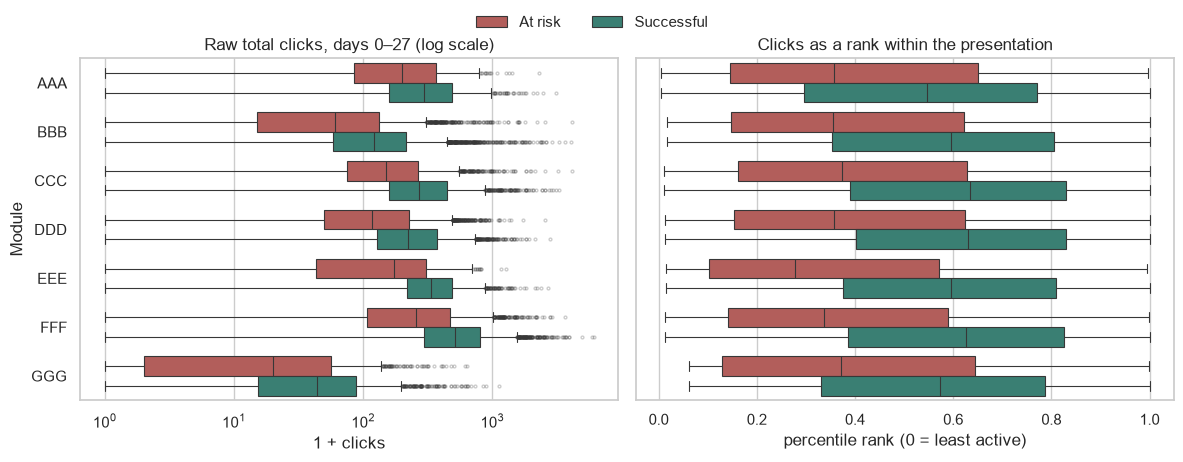

In [39]:
# ---- 6.7  Do the relative features remove the module scale problem? ----
# Raw clicks: medians differ hugely between presentations.
# Percentile ranks: the gap between outcomes is on one common scale.
comparison = (
    features.assign(outcome=features["at_risk"].map({0: "Successful", 1: "At risk"}))
    .groupby(["code_module", "outcome"])
    .agg(median_clicks=("total_clicks_28d", "median"),
         median_click_rank=("total_clicks_28d_pct_in_presentation", "median"))
    .unstack("outcome")
)
display(comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
order = sorted(features["code_module"].unique())
palette = {"At risk": "#C0504D", "Successful": "#2E8B7A"}
plot_df = features.assign(outcome=features["at_risk"].map({0: "Successful", 1: "At risk"}))
for ax, column, title in [
    (axes[0], "total_clicks_28d", "Raw total clicks, days 0–27 (log scale)"),
    (axes[1], "total_clicks_28d_pct_in_presentation", "Clicks as a rank within the presentation"),
]:
    data = plot_df.assign(value=plot_df[column] + (1 if column == "total_clicks_28d" else 0))
    sns.boxplot(data=data, y="code_module", x="value", hue="outcome", order=order,
                hue_order=["At risk", "Successful"], palette=palette, showfliers=True,
                flierprops={"marker": "o", "markersize": 2, "alpha": 0.25},
                ax=ax, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("1 + clicks" if column == "total_clicks_28d" else "percentile rank (0 = least active)")
    ax.set_ylabel("Module" if ax is axes[0] else "")
    if column == "total_clicks_28d":
        ax.set_xscale("log")
    ax.legend_.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

---
# Part 7 · Validation design

| Step | Data | Purpose |
|---|---|---|
| **Development set** | presentations 2013B, 2013J, 2014B | model choice, tuning, feature-set comparison, threshold |
| **5-fold grouped & stratified cross-validation** | inside the development set | `StratifiedGroupKFold`: folds keep the at-risk share balanced **and** every student is in exactly one fold, so no student is in both training and validation data |
| **Final test set** | the four 2014J presentations (latest in OULAD) | **one** evaluation of the pre-specified final model, mimicking prediction for a future cohort |

**Decision rules for this notebook’s baseline analysis:**

1. *Model family*: This notebook uses logistic regression as an interpretable baseline. The final model is selected in Model_Exploration.ipynb using mean ROC-AUC from grouped cross-validation.
2. *Sensitive attributes* Both notebooks use the main 75-feature set with sensitive attributes excluded. This notebook also evaluates the feature set that includes them.
3. *Early score*: kept if it improves cross-validated ROC-AUC. Because OULAD does not record when grades
   were released, a model **without** score features is also evaluated on the test set as a sensitivity check.
4. *Decision threshold*: the one that maximises F1 on the out-of-fold predictions of the development set.
   It is then applied unchanged to the test set.
5. The test set is used in **one cell** only (Part 9.1). Everything after that cell analyses those
   predictions; nothing is re-tuned.
6. **Model comparison.** Part 9 compares the logistic regression baseline, the other models evaluated in this notebook, and the majority-class baseline on 2014J. The final CatBoost results are reported in `Model_Exploration.ipynb`.

In [40]:
import time
import warnings

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

development = features[~is_test].reset_index(drop=True)
test = features[is_test].reset_index(drop=True)
y_dev = development["at_risk"].to_numpy()
y_test = test["at_risk"].to_numpy()
groups_dev = development["id_student"].to_numpy()

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(cv.split(development, y_dev, groups_dev))

split_summary = pd.DataFrame([
    {
        "set": name,
        "presentations": ", ".join(sorted(data["code_presentation"].unique())),
        "module presentations": data["module_presentation"].nunique(),
        "registrations": len(data),
        "students": data["id_student"].nunique(),
        "at-risk rate (%)": round(data["at_risk"].mean() * 100, 1),
    }
    for name, data in [("Development", development), ("Final test", test)]
])
display(split_summary)

fold_summary = pd.DataFrame([
    {
        "fold": k + 1,
        "train rows": len(tr),
        "validation rows": len(va),
        "validation at-risk rate (%)": round(y_dev[va].mean() * 100, 1),
        "students in both train and validation": len(set(groups_dev[tr]) & set(groups_dev[va])),
    }
    for k, (tr, va) in enumerate(cv_folds)
])
display(fold_summary)

# Feature sets used for every model (professor's feedback: compare all models on the same inputs)
FEATURES_75 = [f for f in all_features if f not in sensitive_features]   # main set, no sensitive attributes
FEATURES_80 = list(all_features)                                          # + gender, disability, age, IMD
print(f"Feature sets: {len(FEATURES_75)} features without sensitive attributes, "
      f"{len(FEATURES_80)} with them")

returning = test["id_student"].isin(set(development["id_student"]))
print(f"Test registrations whose student also appears in the development set: "
      f"{returning.sum():,} ({returning.mean():.1%}).")
print("These are students repeating or taking another module later; a deployed model would also "
      "have seen them, so they stay in the test set, and results are also shown without them.")

,set,presentations,module presentations,registrations,students,at-risk rate (%)
0,Development,"2013B, 2013J, 2014B",15,18334,17243,45.8
1,Final test,2014J,7,9219,8869,40.8


,fold,train rows,validation rows,validation at-risk rate (%),students in both train and validation
0,1,14668,3666,45.9,0
1,2,14667,3667,45.8,0
2,3,14667,3667,45.9,0
3,4,14667,3667,45.8,0
4,5,14667,3667,45.8,0


Feature sets: 75 features without sensitive attributes, 80 with them
Test registrations whose student also appears in the development set: 1,287 (14.0%).
These are students repeating or taking another module later; a deployed model would also have seen them, so they stay in the test set, and results are also shown without them.


In [41]:
# ---- 8.1  Model pipelines and evaluation helpers ----
MODEL_NAMES = ["Majority class", "Logistic regression", "Random forest", "Gradient boosting"]


def build_pipeline(model_name, feature_list, **params):
    """Pre-processing + model. All fitting happens inside each training fold."""
    cats = [f for f in feature_list if f in categorical_features]
    nums = [f for f in feature_list if f not in categorical_features]
    ordinal = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

    if model_name == "Majority class":
        return Pipeline([("model", DummyClassifier(strategy="prior"))])
    if model_name == "Logistic regression":
        prep = ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                              ("scale", StandardScaler())]), nums),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
        ])
        model = LogisticRegression(max_iter=5000, **params)
    elif model_name == "Random forest":
        prep = ColumnTransformer([
            ("num", SimpleImputer(strategy="median", add_indicator=True), nums),
            ("cat", ordinal, cats),
        ])
        model = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                       random_state=RANDOM_STATE, **params)
    elif model_name == "Gradient boosting":
        # Missing values are handled natively, so "not applicable" stays distinguishable
        prep = ColumnTransformer([("cat", ordinal, cats), ("num", "passthrough", nums)])
        model = HistGradientBoostingClassifier(
            categorical_features=[True] * len(cats) + [False] * len(nums),
            early_stopping=False, random_state=RANDOM_STATE, **params)
    else:
        raise ValueError(model_name)
    return Pipeline([("prep", prep), ("model", model)])


def classification_metrics(y_true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probability),
        "PR-AUC": average_precision_score(y_true, probability),
        "Brier": brier_score_loss(y_true, probability),
        "Accuracy": accuracy_score(y_true, predicted),
        "Balanced accuracy": balanced_accuracy_score(y_true, predicted),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted),
        "F1": f1_score(y_true, predicted),
        "Flagged (%)": predicted.mean() * 100,
    }


def cross_validate(model_name, feature_list, folds=None, **params):
    """Grouped, stratified 5-fold CV on the development set -> (fold metrics, out-of-fold probs)."""
    oof = np.zeros(len(development))
    rows = []
    for train_idx, valid_idx in (folds if folds is not None else cv_folds):
        pipe = build_pipeline(model_name, feature_list, **params)
        pipe.fit(development.iloc[train_idx][feature_list], y_dev[train_idx])
        oof[valid_idx] = pipe.predict_proba(development.iloc[valid_idx][feature_list])[:, 1]
        rows.append(classification_metrics(y_dev[valid_idx], oof[valid_idx]))
    return pd.DataFrame(rows), oof


def mean_sd(fold_metrics, columns=("ROC-AUC", "PR-AUC", "Brier", "F1", "Recall", "Precision")):
    return {c: f"{fold_metrics[c].mean():.3f} ± {fold_metrics[c].std():.3f}" for c in columns}

### 8.1b Student dependency check
Some students have more than one registration: several modules in the same presentation, or a module
repeated or added in a later presentation. Rows of the same student are **not independent**, because they
share the same person, habits and circumstances. This check measures how strong that dependency is, and
what happens to cross-validation if it is ignored.

In [42]:
# ---- 8.1b  How many students have more than one registration? ----
registrations_per_student = features.groupby("id_student").size()
presentations_per_student = features.groupby("id_student")["code_presentation"].nunique()
multi_students = registrations_per_student[registrations_per_student > 1].index
concurrent_students = features.groupby(["id_student", "code_presentation"]).size()
concurrent_students = concurrent_students[concurrent_students > 1].index.get_level_values("id_student").unique()

dependency_overview = pd.DataFrame({"value": {
    "Registrations": f"{len(features):,}",
    "Students": f"{features['id_student'].nunique():,}",
    "Students with 1 registration": f"{(registrations_per_student == 1).sum():,}",
    "Students with 2 registrations": f"{(registrations_per_student == 2).sum():,}",
    "Students with 3 or more registrations": f"{(registrations_per_student >= 3).sum():,}",
    "Registrations belonging to students with more than one":
        f"{features['id_student'].isin(multi_students).sum():,} "
        f"({features['id_student'].isin(multi_students).mean():.1%})",
    "Students with two modules in the same presentation": f"{len(concurrent_students):,}",
    "Students registered in more than one presentation": f"{(presentations_per_student > 1).sum():,}",
}})
display(dependency_overview)

# ---- Are the outcomes of the same student linked? ----
# Every ordered pair of two different registrations of the same student
multi = features.loc[features["id_student"].isin(multi_students),
                     ["id_student", "module_presentation", "code_presentation", "at_risk"]]
pairs = multi.merge(multi, on="id_student", suffixes=("_a", "_b"))
pairs = pairs[pairs["module_presentation_a"] != pairs["module_presentation_b"]]
pairs["pair type"] = np.where(pairs["code_presentation_a"] == pairs["code_presentation_b"],
                              "same presentation (concurrent modules)", "different presentations")

dependency_rows = []
for pair_type, part in [("all pairs", pairs)] + list(pairs.groupby("pair type")):
    a, b = part["at_risk_a"], part["at_risk_b"]
    dependency_rows.append({
        "pair type": pair_type,
        "pairs": len(part) // 2,
        "P(at risk | other registration at risk)": b[a == 1].mean(),
        "P(at risk | other registration successful)": b[a == 0].mean(),
        "same outcome in both (observed)": (a == b).mean(),
        "same outcome if independent": a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean()),
        "correlation (phi)": np.corrcoef(a, b)[0, 1],
    })
outcome_dependency = pd.DataFrame(dependency_rows).set_index("pair type")
print("Outcome dependency between registrations of the same student")
display(outcome_dependency.round(3))

,value
Registrations,"27,553"
Students,"24,849"
Students with 1 registration,"22,266"
Students with 2 registrations,"2,472"
Students with 3 or more registrations,111
Registrations belonging to students with more than one,"5,287 (19.2%)"
Students with two modules in the same presentation,646
Students registered in more than one presentation,"1,986"


Outcome dependency between registrations of the same student


,pairs,P(at risk | other registration at risk),P(at risk | other registration successful),same outcome in both (observed),same outcome if independent,correlation (phi)
pair type,,,,,,
all pairs,2836,0.709,0.362,0.678,0.506,0.348
different presentations,2186,0.682,0.403,0.645,0.507,0.279
same presentation (concurrent modules),650,0.805,0.229,0.789,0.503,0.576


In [43]:
# ---- 8.1c  What if the dependency were ignored? Plain vs grouped cross-validation ----
from sklearn.model_selection import StratifiedKFold

plain_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                   .split(development, y_dev))
plain_overlap = [len(set(groups_dev[tr]) & set(groups_dev[va])) for tr, va in plain_folds]
grouped_overlap = [len(set(groups_dev[tr]) & set(groups_dev[va])) for tr, va in cv_folds]

grouped_metrics, _ = cross_validate("Logistic regression", FEATURES_75, C=1.0)
plain_metrics, _ = cross_validate("Logistic regression", FEATURES_75, folds=plain_folds, C=1.0)
display(pd.DataFrame({
    "students in both train and validation (per fold, mean)": [np.mean(grouped_overlap), np.mean(plain_overlap)],
    "CV ROC-AUC": [grouped_metrics["ROC-AUC"].mean(), plain_metrics["ROC-AUC"].mean()],
    "CV F1": [grouped_metrics["F1"].mean(), plain_metrics["F1"].mean()],
}, index=["Grouped by student (used)", "Plain stratified (ignores students)"]).round(4))
print("Grouping keeps every student's rows on one side of each split; the final test-set confidence")
print("intervals (Part 9.2) are also computed by resampling students, not rows.")

,"students in both train and validation (per fold, mean)",CV ROC-AUC,CV F1
Grouped by student (used),0.0,0.7889,0.6696
Plain stratified (ignores students),355.8,0.7883,0.6674


Grouping keeps every student's rows on one side of each split; the final test-set confidence
intervals (Part 9.2) are also computed by resampling students, not rows.


# Part 8 · Model development (cross-validation on 2013B, 2013J, 2014B)

### 8.2 Model families and tuning
Each family is tuned with a small grid on the **same 75 features** (all candidates except the 5 sensitive
attributes), so every model sees identical inputs. Every grid point is scored with the same grouped,
stratified 5-fold CV, so all models are compared on identical folds. (Runtime: a few minutes.)

In [44]:
param_grids = {
    "Majority class": [{}],
    "Logistic regression": [{"C": c} for c in [0.01, 0.1, 1.0, 10.0]],
    "Random forest": [
        {"min_samples_leaf": leaf, "max_features": mf}
        for leaf in [5, 20] for mf in ["sqrt", 0.3]
    ],
    "Gradient boosting": [
        {"learning_rate": 0.05, "max_iter": it, "max_leaf_nodes": leaves,
         "min_samples_leaf": leaf, "l2_regularization": l2}
        for it in [200, 500] for leaves in [15, 31] for leaf in [20, 80] for l2 in [0.0, 1.0]
    ],
}

tuning_rows, best_params, cv_results, oof_predictions = [], {}, {}, {}
for model_name in MODEL_NAMES:
    start = time.time()
    best_auc = -np.inf
    for params in param_grids[model_name]:
        fold_metrics, oof = cross_validate(model_name, FEATURES_75, **params)
        auc = fold_metrics["ROC-AUC"].mean()
        tuning_rows.append({"model": model_name, "params": params, "cv ROC-AUC": auc})
        if auc > best_auc:
            best_auc, best_params[model_name] = auc, params
            cv_results[model_name], oof_predictions[model_name] = fold_metrics, oof
    print(f"{model_name:20s} {len(param_grids[model_name]):2d} settings  "
          f"best ROC-AUC {best_auc:.4f}  ({time.time() - start:.0f}s)  {best_params[model_name]}")

tuning_results = pd.DataFrame(tuning_rows)

Majority class        1 settings  best ROC-AUC 0.5000  (0s)  {}
Logistic regression   4 settings  best ROC-AUC 0.7889  (7s)  {'C': 1.0}
Random forest         4 settings  best ROC-AUC 0.7863  (87s)  {'min_samples_leaf': 20, 'max_features': 0.3}
Gradient boosting    16 settings  best ROC-AUC 0.7928  (198s)  {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 1.0}


,ROC-AUC,PR-AUC,Brier,F1,Recall,Precision
"model (tuned, 75 features)",,,,,,
Majority class,0.500 ± 0.000,0.458 ± 0.000,0.248 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic regression,0.789 ± 0.003,0.773 ± 0.009,0.185 ± 0.002,0.670 ± 0.006,0.616 ± 0.009,0.734 ± 0.007
Random forest,0.786 ± 0.002,0.775 ± 0.006,0.186 ± 0.001,0.667 ± 0.003,0.611 ± 0.006,0.734 ± 0.003
Gradient boosting,0.793 ± 0.002,0.781 ± 0.006,0.183 ± 0.001,0.676 ± 0.004,0.626 ± 0.005,0.734 ± 0.008


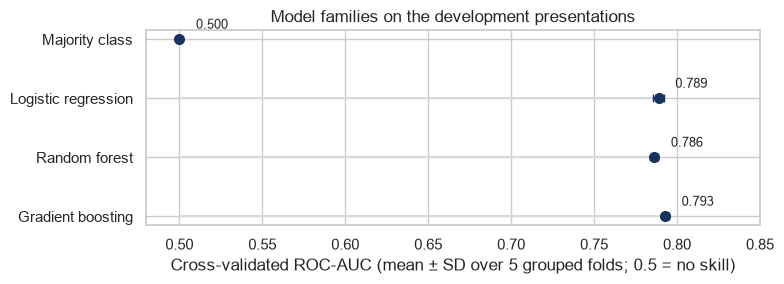

In [45]:
model_comparison = pd.DataFrame({m: mean_sd(cv_results[m]) for m in MODEL_NAMES}).T
model_comparison.index.name = "model (tuned, 75 features)"
display(model_comparison)

fig, ax = plt.subplots(figsize=(8, 3.0))
means = [cv_results[m]["ROC-AUC"].mean() for m in MODEL_NAMES]
sds = [cv_results[m]["ROC-AUC"].std() for m in MODEL_NAMES]
y_pos = np.arange(len(MODEL_NAMES))
ax.hlines(y_pos, 0.5, means, color="#D5DBE1", lw=1.5)
ax.errorbar(means, y_pos, xerr=sds, fmt="o", color="#17345F", ms=7, capsize=3)
for y0, value in zip(y_pos, means):
    ax.text(value + 0.01, y0 - 0.18, f"{value:.3f}", fontsize=9)
ax.set_yticks(y_pos, MODEL_NAMES)
ax.set_xlim(0.48, 0.85)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated ROC-AUC (mean ± SD over 5 grouped folds; 0.5 = no skill)")
ax.set_title("Model families on the development presentations")
plt.tight_layout()
plt.show()

In [46]:
# ---- 8.2b  Every model with and without sensitive attributes (and without score features) ----
FEATURE_VARIANTS = {
    "75 features (without sensitive)": FEATURES_75,
    "80 features (with sensitive)": FEATURES_80,
    "73 features (without sensitive, without score)": [f for f in FEATURES_75 if f not in score_features],
}
FAMILIES = [m for m in MODEL_NAMES if m != "Majority class"]

variant_cv, variant_oof = {}, {}
for family in FAMILIES:
    for variant, feature_list in FEATURE_VARIANTS.items():
        if variant.startswith("75"):
            fold_metrics, oof = cv_results[family], oof_predictions[family]   # already computed above
        else:
            fold_metrics, oof = cross_validate(family, feature_list, **best_params[family])
        variant_cv[(family, variant)], variant_oof[(family, variant)] = fold_metrics, oof

variant_table = pd.DataFrame([
    {"model": family, "feature set": variant,
     **{k: v for k, v in mean_sd(variant_cv[(family, variant)], ("ROC-AUC", "PR-AUC", "F1")).items()},
     "Accuracy": f"{variant_cv[(family, variant)]['Accuracy'].mean():.3f}"}
    for family in FAMILIES for variant in FEATURE_VARIANTS
]).set_index(["model", "feature set"])
print("Cross-validated performance of every model on each feature set (threshold 0.5)")
display(variant_table)

sensitive_effect = pd.DataFrame({
    family: {
        "ROC-AUC without sensitive (75)": variant_cv[(family, "75 features (without sensitive)")]["ROC-AUC"].mean(),
        "ROC-AUC with sensitive (80)": variant_cv[(family, "80 features (with sensitive)")]["ROC-AUC"].mean(),
    } for family in FAMILIES
}).T
sensitive_effect["difference"] = (sensitive_effect["ROC-AUC with sensitive (80)"]
                                  - sensitive_effect["ROC-AUC without sensitive (75)"])
display(sensitive_effect.round(4))

Cross-validated performance of every model on each feature set (threshold 0.5)


ROC-AUC  \
model               feature set                                                     
Logistic regression 75 features (without sensitive)                 0.789 ± 0.003   
                    80 features (with sensitive)                    0.792 ± 0.003   
                    73 features (without sensitive, without score)  0.762 ± 0.007   
Random forest       75 features (without sensitive)                 0.786 ± 0.002   
                    80 features (with sensitive)                    0.788 ± 0.002   
                    73 features (without sensitive, without score)  0.760 ± 0.006   
Gradient boosting   75 features (without sensitive)                 0.793 ± 0.002   
                    80 features (with sensitive)                    0.795 ± 0.002   
                    73 features (without sensitive, without score)  0.767 ± 0.006   

                                                                           PR-AUC  \
model               feature set                                                     
Logistic regression 75 features (without sensitive)                 0.773 ± 0.009   
                    80 features (with sensitive)                    0.776 ± 0.008   
                    73 features (without sensitive, without score)  0.746 ± 0.010   
Random forest       75 features (without sensitive)                 0.775 ± 0.006   
                    80 features (with sensitive)                    0.776 ± 0.006   
                    73 features (without sensitive, without score)  0.748 ± 0.009   
Gradient boosting   75 features (without sensitive)                 0.781 ± 0.006   
                    80 features (with sensitive)                    0.783 ± 0.006   
                    73 features (without sensitive, without score)  0.753 ± 0.007   

                                                                               F1  \
model               feature set                                                     
Logistic regression 75 features (without sensitive)                 0.670 ± 0.006   
                    80 features (with sensitive)                    0.673 ± 0.004   
                    73 features (without sensitive, without score)  0.644 ± 0.009   
Random forest       75 features (without sensitive)                 0.667 ± 0.003   
                    80 features (with sensitive)                    0.666 ± 0.004   
                    73 features (without sensitive, without score)  0.642 ± 0.007   
Gradient boosting   75 features (without sensitive)                 0.676 ± 0.004   
                    80 features (with sensitive)                    0.680 ± 0.002   
                    73 features (without sensitive, without score)  0.649 ± 0.006   

                                                                   Accuracy  
model               feature set                                              
Logistic regression 75 features (without sensitive)                   0.722  
                    80 features (with sensitive)                      0.723  
                    73 features (without sensitive, without score)    0.700  
Random forest       75 features (without sensitive)                   0.720  
                    80 features (with sensitive)                      0.720  
                    73 features (without sensitive, without score)    0.701  
Gradient boosting   75 features (without sensitive)                   0.725  
                    80 features (with sensitive)                      0.726  
                    73 features (without sensitive, without score)    0.702

,ROC-AUC without sensitive (75),ROC-AUC with sensitive (80),difference
Logistic regression,0.7889,0.7915,0.0026
Random forest,0.7863,0.7883,0.0020
Gradient boosting,0.7928,0.7950,0.0023


In [47]:
# 8.3 Logistic regression baseline
cv_auc = {
    model: cv_results[model]["ROC-AUC"].mean()
    for model in MODEL_NAMES
    if model != "Majority class"
}

FINAL_FAMILY = "Logistic regression"
FINAL_PARAMS = best_params[FINAL_FAMILY]

print(f"Baseline model: {FINAL_FAMILY} {FINAL_PARAMS}")

Baseline model: Logistic regression {'C': 1.0}


### 8.4 What does each group of information add? (feature-set comparison)
All variants use the selected model family and its tuned settings, on the same CV folds.
The key comparison for the EDA's recommendation is **raw clicks vs engagement relative to the presentation**,
with and without module context.

,features,ROC-AUC,PR-AUC,F1
feature set,,,,
Enrolment information only (background + module),16,0.661 ± 0.009,0.613 ± 0.005,0.546 ± 0.010
+ engagement as raw clicks,54,0.754 ± 0.007,0.732 ± 0.008,0.642 ± 0.007
+ engagement relative to presentation,55,0.753 ± 0.005,0.731 ± 0.008,0.643 ± 0.006
"+ engagement, raw and relative",73,0.755 ± 0.007,0.733 ± 0.009,0.643 ± 0.006
+ early assessment = full model,80,0.792 ± 0.003,0.776 ± 0.008,0.673 ± 0.004
Full model without score features,78,0.767 ± 0.006,0.751 ± 0.008,0.649 ± 0.005
Full model without sensitive attributes,75,0.789 ± 0.003,0.773 ± 0.009,0.670 ± 0.006
No module context: raw clicks,49,0.731 ± 0.007,0.702 ± 0.006,0.619 ± 0.010
No module context: relative engagement,50,0.747 ± 0.005,0.724 ± 0.009,0.637 ± 0.006


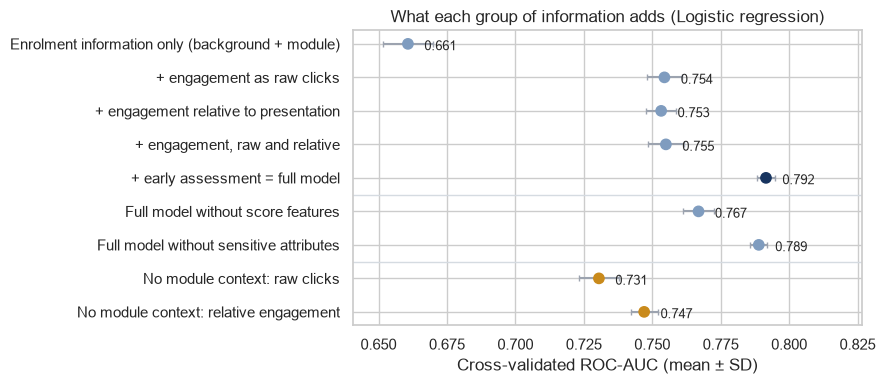

In [48]:
pre_course_absolute = ["pre_start_clicks", "log_pre_start_clicks", "pre_start_active_days"]
pre_course_relative = ["pre_start_clicks_pct_in_presentation", "pre_start_clicks_z_in_presentation"]
enrolment = feature_groups["Background"] + feature_groups["Module context"]
scale_free_engagement = feature_groups["Engagement timing & regularity"] + feature_groups["Resource mix"]
raw_engagement = feature_groups["Engagement (absolute)"] + pre_course_absolute
relative_engagement = feature_groups["Engagement (relative to presentation)"] + pre_course_relative

feature_sets = {
    "Enrolment information only (background + module)": enrolment,
    "+ engagement as raw clicks": enrolment + scale_free_engagement + raw_engagement,
    "+ engagement relative to presentation": enrolment + scale_free_engagement + relative_engagement,
    "+ engagement, raw and relative": enrolment + scale_free_engagement + raw_engagement + relative_engagement,
    "+ early assessment = full model": all_features,
    "Full model without score features": [f for f in all_features if f not in score_features],
    "Full model without sensitive attributes": [f for f in all_features if f not in sensitive_features],
    "No module context: raw clicks": feature_groups["Background"] + scale_free_engagement + raw_engagement,
    "No module context: relative engagement": feature_groups["Background"] + scale_free_engagement + relative_engagement,
}

ablation_rows, ablation_folds = [], {}
for name, feature_list in feature_sets.items():
    fold_metrics, _ = cross_validate(FINAL_FAMILY, feature_list, **FINAL_PARAMS)
    ablation_folds[name] = fold_metrics
    ablation_rows.append({"feature set": name, "features": len(feature_list),
                          **mean_sd(fold_metrics, ("ROC-AUC", "PR-AUC", "F1"))})
ablation = pd.DataFrame(ablation_rows).set_index("feature set")
display(ablation)

fig, ax = plt.subplots(figsize=(9, 4.0))
names = list(feature_sets)
values = [ablation_folds[n]["ROC-AUC"].mean() for n in names]
errors = [ablation_folds[n]["ROC-AUC"].std() for n in names]
colors = ["#17345F" if n.startswith("+ early") else "#C98A1B" if n.startswith("No module") else "#7F9CBF"
          for n in names]
y_pos = np.arange(len(names))
ax.errorbar(values, y_pos, xerr=errors, fmt="none", ecolor="#9CA3AF", capsize=2)
ax.scatter(values, y_pos, c=colors, s=55, zorder=3)
for y0, value in zip(y_pos, values):
    ax.text(value + 0.006, y0 + 0.08, f"{value:.3f}", va="center", fontsize=9)
ax.axhline(4.5, color="#D5DBE1", lw=1)
ax.axhline(6.5, color="#D5DBE1", lw=1)
ax.set_yticks(y_pos, names)
ax.set_xlim(min(values) - 0.02, max(values) + 0.035)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated ROC-AUC (mean ± SD)")
ax.set_title(f"What each group of information adds ({FINAL_FAMILY})")
plt.tight_layout()
plt.show()

In [49]:
# ---- 8.5  Rules 2 and 3: sensitive attributes and score features ----
full_auc = ablation_folds["+ early assessment = full model"]["ROC-AUC"].mean()
no_sensitive_auc = ablation_folds["Full model without sensitive attributes"]["ROC-AUC"].mean()
no_score_auc = ablation_folds["Full model without score features"]["ROC-AUC"].mean()

drop_sensitive = True
keep_score = no_score_auc < full_auc

FINAL_FEATURES = [f for f in all_features
                  if not (drop_sensitive and f in sensitive_features)
                  and (keep_score or f not in score_features)]

print(f"Removing sensitive attributes changes CV ROC-AUC by {no_sensitive_auc - full_auc:+.4f} "
      f"-> {'left out' if drop_sensitive else 'kept'}")
print(f"Removing score features changes CV ROC-AUC by {no_score_auc - full_auc:+.4f} "
      f"-> {'kept' if keep_score else 'left out'}")
print(f"Final feature set: {len(FINAL_FEATURES)} features")
assert FINAL_FEATURES == FEATURES_75, "final model should use the same 75 features as the comparison"

Removing sensitive attributes changes CV ROC-AUC by -0.0026 -> left out
Removing score features changes CV ROC-AUC by -0.0246 -> kept
Final feature set: 75 features


In [50]:
# ---- 8.6  Rule 4: decision threshold from out-of-fold predictions ----
final_cv_metrics, final_oof = cross_validate(FINAL_FAMILY, FINAL_FEATURES, **FINAL_PARAMS)

precision_curve, recall_curve, thresholds = precision_recall_curve(y_dev, final_oof)
f1_curve = 2 * precision_curve * recall_curve / np.clip(precision_curve + recall_curve, 1e-12, None)
best = np.argmax(f1_curve[:-1])
THRESHOLD = float(thresholds[best])

print(f"Final configuration, cross-validated: {mean_sd(final_cv_metrics)}")
print(f"Decision threshold (max out-of-fold F1): {THRESHOLD:.3f}")
display(pd.DataFrame({
    "threshold 0.50": classification_metrics(y_dev, final_oof, 0.5),
    f"threshold {THRESHOLD:.2f} (selected)": classification_metrics(y_dev, final_oof, THRESHOLD),
}).round(3))

Final configuration, cross-validated: {'ROC-AUC': '0.789 ± 0.003', 'PR-AUC': '0.773 ± 0.009', 'Brier': '0.185 ± 0.002', 'F1': '0.670 ± 0.006', 'Recall': '0.616 ± 0.009', 'Precision': '0.734 ± 0.007'}
Decision threshold (max out-of-fold F1): 0.360


,threshold 0.50,threshold 0.36 (selected)
ROC-AUC,0.789,0.789
PR-AUC,0.773,0.773
Brier,0.185,0.185
Accuracy,0.722,0.698
Balanced accuracy,0.713,0.705
Precision,0.734,0.638
Recall,0.616,0.789
F1,0.670,0.705
Flagged (%),38.453,56.703


---
# Part 9 · Logistic regression baseline evaluation on 2014J.

### 9.1 The one test-set cell
Every model is refitted on **all** development presentations with the settings chosen above, then scores the
2014J registrations once. Each variant uses the threshold chosen from its own out-of-fold development
predictions, never from the test set.

In [51]:
reference_family = max((m for m in cv_auc if m != FINAL_FAMILY), key=cv_auc.get)


def oof_threshold(oof):
    """Threshold that maximises F1 on out-of-fold development predictions."""
    p, r, t = precision_recall_curve(y_dev, oof)
    return float(t[np.argmax((2 * p * r / np.clip(p + r, 1e-12, None))[:-1])])


# Every model family on every feature set, plus the baseline
test_models = {
    (family, variant): (family, feature_list, best_params[family])
    for family in FAMILIES for variant, feature_list in FEATURE_VARIANTS.items()
}
test_models[("Majority class", "-")] = ("Majority class", FEATURES_75, {})

fitted_models, test_probability, model_thresholds = {}, {}, {}
for key, (family, feature_list, params) in test_models.items():
    # threshold from this model's own out-of-fold development predictions
    model_thresholds[key] = 0.5 if family == "Majority class" else oof_threshold(variant_oof[key])
    pipe = build_pipeline(family, feature_list, **params)
    pipe.fit(development[feature_list], y_dev)
    fitted_models[key] = pipe
    test_probability[key] = pipe.predict_proba(test[feature_list])[:, 1]

# Names used in the analysis below
FINAL_KEY = (FINAL_FAMILY, "75 features (without sensitive)")
assert abs(model_thresholds[FINAL_KEY] - THRESHOLD) < 1e-9
for alias, key in {
    "Final model": FINAL_KEY,
    "Sensitivity: without score features": (FINAL_FAMILY, "73 features (without sensitive, without score)"),
    f"Reference: {reference_family.lower()}": (reference_family, "75 features (without sensitive)"),
}.items():
    test_probability[alias], model_thresholds[alias] = test_probability[key], model_thresholds[key]
    fitted_models[alias] = fitted_models[key]

final_model = fitted_models["Final model"]
p_test = test_probability["Final model"]
flag_test = (p_test >= THRESHOLD).astype(int)
print(f"Test predictions created for {len(test_models)} models "
      f"({len(FAMILIES)} families x {len(FEATURE_VARIANTS)} feature sets + baseline)")

Test predictions created for 10 models (3 families x 3 feature sets + baseline)


### 9.2 Test-set performance

In [52]:
test_results = pd.DataFrame([
    {"model": key[0], "feature set": key[1],
     "features": 0 if key[0] == "Majority class" else len(test_models[key][1]),
     "threshold": model_thresholds[key],
     **classification_metrics(y_test, test_probability[key], model_thresholds[key])}
    for key in test_models
]).set_index(["model", "feature set"])
print(f"Test-set performance (2014J) of every model and feature set. Logistic regression baseline: {FINAL_FAMILY}, 75 features.")
display(test_results.round(3))

print("Test ROC-AUC and accuracy by model and feature set")
display(pd.concat({
    "ROC-AUC": test_results["ROC-AUC"].drop(index="Majority class", level=0).unstack("feature set"),
    "Accuracy": test_results["Accuracy"].drop(index="Majority class", level=0).unstack("feature set"),
}, axis=1).round(3))

cv_vs_test = pd.DataFrame({
    "cross-validation (development)": classification_metrics(y_dev, final_oof, THRESHOLD),
    "final test (2014J)": classification_metrics(y_test, p_test, THRESHOLD),
}).round(3)
print("Logistic regression baseline: cross-validation vs test")
display(cv_vs_test)
print(f"Majority-class accuracy on the test set: {1 - y_test.mean():.3f}")

# 95% confidence intervals: bootstrap over students (a student's registrations stay together)
student_index = pd.Series(np.arange(len(test))).groupby(test["id_student"].to_numpy()).apply(np.array).tolist()
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    pick = rng.integers(0, len(student_index), len(student_index))
    idx = np.concatenate([student_index[i] for i in pick])
    m = classification_metrics(y_test[idx], p_test[idx], THRESHOLD)
    boot.append(m)
boot = pd.DataFrame(boot)
point = classification_metrics(y_test, p_test, THRESHOLD)
final_ci = pd.DataFrame({
    "estimate": point,
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
}).loc[["ROC-AUC", "PR-AUC", "Brier", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]]
print("Logistic regression baseline: test set with student-level bootstrap 95% CIs (1,000 resamples)")
display(final_ci.round(3))

cm = confusion_matrix(y_test, flag_test)
display(pd.DataFrame(cm, index=["Actually successful", "Actually at risk"],
                     columns=["Predicted successful", "Flagged at risk"]))

Test-set performance (2014J) of every model and feature set. Logistic regression baseline: Logistic regression, 75 features.


features  \
model               feature set                                                
Logistic regression 75 features (without sensitive)                       75   
                    80 features (with sensitive)                          80   
                    73 features (without sensitive, without score)        73   
Random forest       75 features (without sensitive)                       75   
                    80 features (with sensitive)                          80   
                    73 features (without sensitive, without score)        73   
Gradient boosting   75 features (without sensitive)                       75   
                    80 features (with sensitive)                          80   
                    73 features (without sensitive, without score)        73   
Majority class      -                                                      0   

                                                                    threshold  \
model               feature set                                                 
Logistic regression 75 features (without sensitive)                     0.360   
                    80 features (with sensitive)                        0.343   
                    73 features (without sensitive, without score)      0.340   
Random forest       75 features (without sensitive)                     0.362   
                    80 features (with sensitive)                        0.376   
                    73 features (without sensitive, without score)      0.347   
Gradient boosting   75 features (without sensitive)                     0.358   
                    80 features (with sensitive)                        0.348   
                    73 features (without sensitive, without score)      0.353   
Majority class      -                                                   0.500   

                                                                    ROC-AUC  \
model               feature set                                               
Logistic regression 75 features (without sensitive)                   0.763   
                    80 features (with sensitive)                      0.766   
                    73 features (without sensitive, without score)    0.746   
Random forest       75 features (without sensitive)                   0.768   
                    80 features (with sensitive)                      0.770   
                    73 features (without sensitive, without score)    0.745   
Gradient boosting   75 features (without sensitive)                   0.773   
                    80 features (with sensitive)                      0.777   
                    73 features (without sensitive, without score)    0.749   
Majority class      -                                                 0.500   

                                                                    PR-AUC  \
model               feature set                                              
Logistic regression 75 features (without sensitive)                  0.711   
                    80 features (with sensitive)                     0.715   
                    73 features (without sensitive, without score)   0.689   
Random forest       75 features (without sensitive)                  0.717   
                    80 features (with sensitive)                     0.721   
                    73 features (without sensitive, without score)   0.689   
Gradient boosting   75 features (without sensitive)                  0.727   
                    80 features (with sensitive)                     0.731   
                    73 features (without sensitive, without score)   0.697   
Majority class      -                                                0.408   

                                                                    Brier  \
model               feature set                                             
Logistic regression 75 features (without sensitive)                 0.190   
                 

Test ROC-AUC and accuracy by model and feature set


ROC-AUC  \
feature set         75 features (without sensitive)   
model                                                 
Logistic regression                           0.763   
Random forest                                 0.768   
Gradient boosting                             0.773   

                                                  \
feature set         80 features (with sensitive)   
model                                              
Logistic regression                        0.766   
Random forest                              0.770   
Gradient boosting                          0.777   

                                                                    \
feature set         73 features (without sensitive, without score)   
model                                                                
Logistic regression                                          0.746   
Random forest                                                0.745   
Gradient boosting                                            0.749   

                                           Accuracy  \
feature set         75 features (without sensitive)   
model                                                 
Logistic regression                           0.696   
Random forest                                 0.665   
Gradient boosting                             0.673   

                                                  \
feature set         80 features (with sensitive)   
model                                              
Logistic regression                        0.688   
Random forest                              0.672   
Gradient boosting                          0.675   

                                                                    
feature set         73 features (without sensitive, without score)  
model                                                               
Logistic regression                                          0.640  
Random forest                                                0.618  
Gradient boosting                                            0.635

Logistic regression baseline: cross-validation vs test


,cross-validation (development),final test (2014J)
ROC-AUC,0.789,0.763
PR-AUC,0.773,0.711
Brier,0.185,0.190
Accuracy,0.698,0.696
Balanced accuracy,0.705,0.696
Precision,0.638,0.612
Recall,0.789,0.696
F1,0.705,0.651
Flagged (%),56.703,46.382


Majority-class accuracy on the test set: 0.592
Logistic regression baseline: test set with student-level bootstrap 95% CIs (1,000 resamples)


,estimate,95% CI low,95% CI high
ROC-AUC,0.763,0.753,0.774
PR-AUC,0.711,0.696,0.727
Brier,0.190,0.185,0.194
Accuracy,0.696,0.687,0.706
Balanced accuracy,0.696,0.687,0.706
Precision,0.612,0.597,0.627
Recall,0.696,0.681,0.710
F1,0.651,0.638,0.663


,Predicted successful,Flagged at risk
Actually successful,3799,1658
Actually at risk,1144,2618


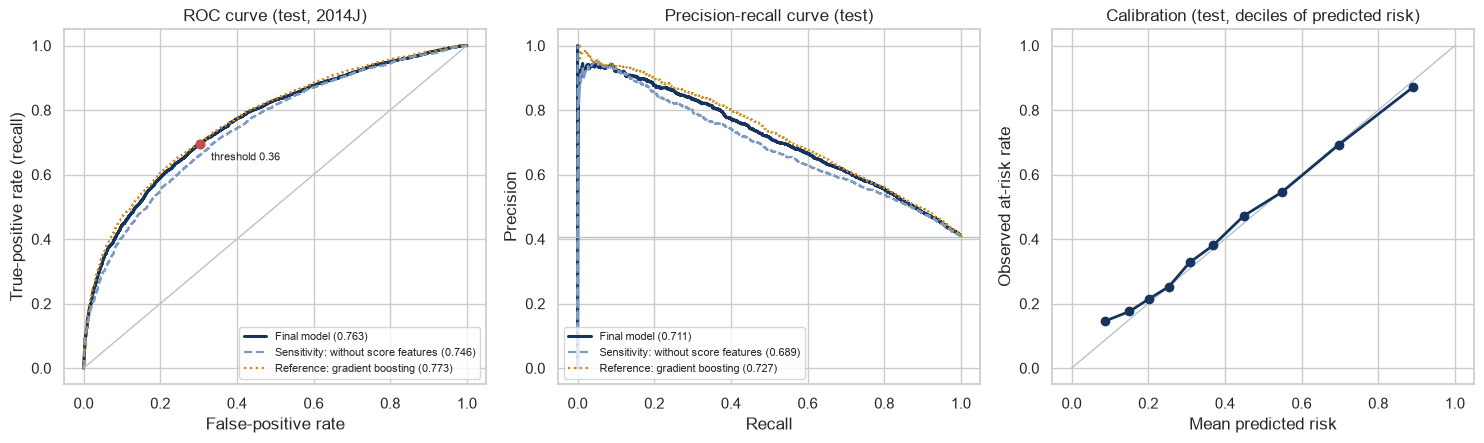

In [53]:
# ---- 9.3  ROC, precision-recall and calibration on the test set ----
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
line_styles = {
    "Final model": dict(color="#17345F", lw=2.2),
    "Sensitivity: without score features": dict(color="#7F9CBF", lw=1.6, ls="--"),
    f"Reference: {reference_family.lower()}": dict(color="#C98A1B", lw=1.6, ls=":"),
}
for name, style in line_styles.items():
    fpr, tpr, _ = roc_curve(y_test, test_probability[name])
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, test_probability[name]):.3f})", **style)
    prec, rec, _ = precision_recall_curve(y_test, test_probability[name])
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, test_probability[name]):.3f})", **style)
axes[0].plot([0, 1], [0, 1], color="#B8C2CC", lw=1)
axes[0].set(title="ROC curve (test, 2014J)", xlabel="False-positive rate", ylabel="True-positive rate (recall)")
axes[1].axhline(y_test.mean(), color="#B8C2CC", lw=1)
axes[1].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="lower left")
fpr_t = ((flag_test == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
axes[0].scatter([fpr_t], [recall_score(y_test, flag_test)], color="#C0504D", zorder=5, s=40)
axes[0].annotate(f"threshold {THRESHOLD:.2f}", (fpr_t, recall_score(y_test, flag_test)),
                 textcoords="offset points", xytext=(8, -12), fontsize=8)

observed, predicted = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[2].plot([0, 1], [0, 1], color="#B8C2CC", lw=1)
axes[2].plot(predicted, observed, marker="o", color="#17345F", lw=2)
axes[2].set(title="Calibration (test, deciles of predicted risk)",
            xlabel="Mean predicted risk", ylabel="Observed at-risk rate")
plt.tight_layout()
plt.show()

In [54]:
# ---- 9.4  If advisers can only contact some students: precision and recall by capacity ----
order = np.argsort(-p_test)
capacity_rows = []
for share in [0.10, 0.20, 0.30, 0.40, flag_test.mean()]:
    k = int(round(share * len(p_test)))
    chosen = np.zeros(len(p_test), dtype=int)
    chosen[order[:k]] = 1
    capacity_rows.append({
        "students contacted": f"top {share:.0%}" if share != flag_test.mean() else f"threshold {THRESHOLD:.2f} ({share:.0%})",
        "registrations": k,
        "precision (share truly at risk)": precision_score(y_test, chosen),
        "recall (share of all at-risk found)": recall_score(y_test, chosen),
    })
capacity = pd.DataFrame(capacity_rows).set_index("students contacted")
display(capacity.round(3))

,registrations,precision (share truly at risk),recall (share of all at-risk found)
students contacted,,,
top 10%,922,0.872,0.214
top 20%,1844,0.783,0.384
top 30%,2766,0.704,0.517
top 40%,3688,0.646,0.633
threshold 0.36 (46%),4276,0.612,0.696


### 9.5 Performance by module and presentation (hypothesis H7)

,registrations,at-risk rate,ROC-AUC,PR-AUC,flagged,recall (TPR),false-positive rate,precision,ROC-AUC without score
code_module,,,,,,,,,
AAA,348,0.273,0.704,0.522,0.296,0.516,0.213,0.476,0.684
BBB,1787,0.355,0.704,0.612,0.283,0.466,0.182,0.585,0.706
CCC,2023,0.498,0.803,0.792,0.467,0.702,0.233,0.750,0.727
DDD,1463,0.459,0.788,0.767,0.596,0.815,0.410,0.627,0.750
EEE,1021,0.330,0.752,0.637,0.449,0.706,0.322,0.520,0.752
FFF,1860,0.399,0.800,0.746,0.548,0.808,0.376,0.588,0.792
GGG,717,0.381,0.672,0.572,0.520,0.659,0.435,0.483,0.671


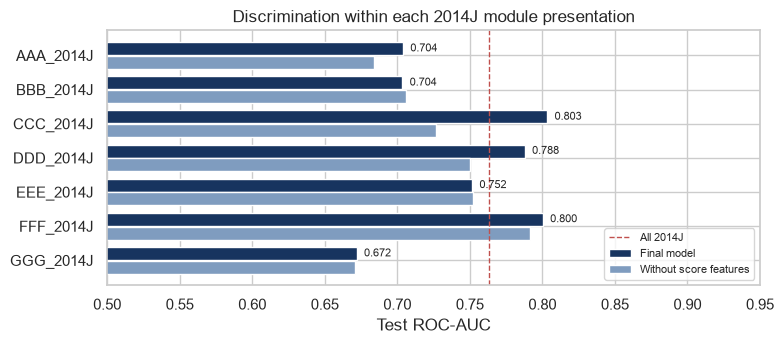

In [55]:
def group_metrics(frame, probability, by, threshold=THRESHOLD):
    rows = []
    for key, part in frame.groupby(by, observed=True):
        y, p = part["at_risk"].to_numpy(), probability[part.index]
        flag = (p >= threshold).astype(int)
        rows.append({
            by: key, "registrations": len(part), "at-risk rate": y.mean(),
            "ROC-AUC": roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan,
            "PR-AUC": average_precision_score(y, p) if 0 < y.mean() < 1 else np.nan,
            "flagged": flag.mean(),
            "recall (TPR)": recall_score(y, flag, zero_division=0),
            "false-positive rate": flag[y == 0].mean() if (y == 0).any() else np.nan,
            "precision": precision_score(y, flag, zero_division=0),
        })
    return pd.DataFrame(rows).set_index(by)


by_module = group_metrics(test, p_test, "code_module")
by_module["ROC-AUC without score"] = group_metrics(
    test, test_probability["Sensitivity: without score features"], "code_module")["ROC-AUC"]
display(by_module.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
y_pos = np.arange(len(by_module))
ax.barh(y_pos, by_module["ROC-AUC"], color="#17345F", height=0.38, label="Final model")
ax.barh(y_pos + 0.4, by_module["ROC-AUC without score"], color="#7F9CBF", height=0.38,
        label="Without score features")
for y0, v in zip(y_pos, by_module["ROC-AUC"]):
    ax.text(v + 0.005, y0, f"{v:.3f}", va="center", fontsize=8)
ax.axvline(roc_auc_score(y_test, p_test), color="#C0504D", lw=1, ls="--", label="All 2014J")
ax.set_yticks(y_pos + 0.2, [f"{m}_2014J" for m in by_module.index])
ax.invert_yaxis()
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("Test ROC-AUC")
ax.set_title("Discrimination within each 2014J module presentation")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 9.6 Fairness: performance by demographic group (hypothesis H8)
Sensitive attributes were not model inputs (rule 2), but other features can still act as proxies, so error
rates are compared across groups. *Recall* = share of at-risk students who are flagged (missed students do not
get help); *false-positive rate* = share of successful students flagged (unnecessary contact).

registrations  \
attribute                    group                                  
Gender                       F                               3876   
                             M                               5343   
Age band                     0-35                            6314   
                             35-55                           2818   
                             55<=                              87   
Disability                   No                              8362   
                             Yes                              857   
IMD band (grouped)           0-30% (most deprived)           2706   
                             30-70%                          3716   
                             70-100%                         2431   
                             Unknown                          366   
Previous education (grouped) A level                         4086   
                             Below A level                   3461   
                             HE or postgraduate              1672   

                                                    at-risk rate  ROC-AUC  \
attribute                    group                                          
Gender                       F                             0.385    0.740   
                             M                             0.425    0.779   
Age band                     0-35                          0.422    0.763   
                             35-55                         0.378    0.762   
                             55<=                          0.356    0.803   
Disability                   No                            0.396    0.762   
                             Yes                           0.529    0.762   
IMD band (grouped)           0-30% (most deprived)         0.475    0.773   
                             30-70%                        0.402    0.756   
                             70-100%                       0.360    0.766   
                             Unknown                       0.287    0.692   
Previous education (grouped) A level                       0.374    0.762   
                             Below A level                 0.484    0.756   
                             HE or postgraduate            0.334    0.753   

                                                    PR-AUC  flagged  \
attribute                    group                                    
Gender                       F                       0.668    0.405   
                             M                       0.738    0.506   
Age band                     0-35                    0.724    0.506   
                             35-55                   0.682    0.376   
                             55<=                    0.756    0.230   
Disability                   No                      0.702    0.453   
                             Yes                     0.783    0.568   
IMD band (grouped)           0-30% (most deprived)   0.777    0.511   
                             30-70%                  0.700    0.467   
                             70-100%                 0.664    0.433   
                             Unknown                 0.540    0.284   
Previous education (grouped) A level                 0.680    0.417   
                             Below A level           0.767    0.612   
                             HE or postgraduate      0.613    0.272   

                                                    recall (TPR)  \
attribute                    group                                 
Gender                       F                             0.619   
                             M                             0.746   
Age band                     0-35                          0.729   
                             35-55                         0.617   
                             55<=                          0.516   
Disability                   No                            0.688   
                             Yes 

Largest gap between groups (max - min):


,recall_gap,fpr_gap,auc_gap
attribute,,,
Age band,0.213,0.272,0.041
Disability,0.067,0.059,0.001
Gender,0.127,0.058,0.039
IMD band (grouped),0.253,0.111,0.080
Previous education (grouped),0.263,0.305,0.009


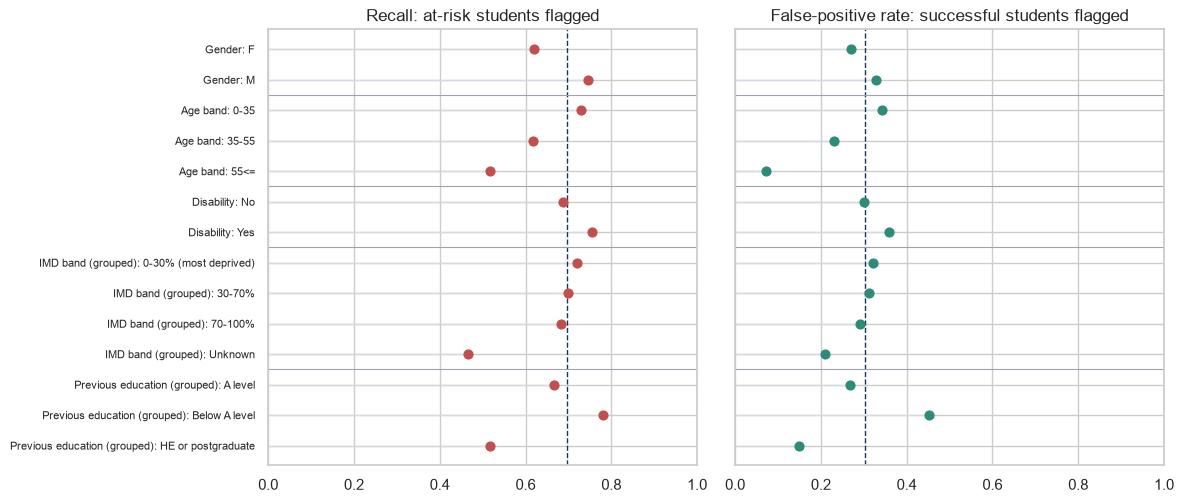

In [56]:
fairness_frame = test.copy()
fairness_frame["IMD band (grouped)"] = pd.cut(
    fairness_frame["imd_decile"], bins=[-1, 2, 6, 9], labels=["0-30% (most deprived)", "30-70%", "70-100%"]
).astype("object").fillna("Unknown")
fairness_frame["Previous education (grouped)"] = fairness_frame["highest_education"].replace({
    "No Formal quals": "Below A level", "Lower Than A Level": "Below A level",
    "A Level or Equivalent": "A level", "HE Qualification": "HE or postgraduate",
    "Post Graduate Qualification": "HE or postgraduate",
})
fairness_frame["Gender"] = fairness_frame["gender"]
fairness_frame["Age band"] = fairness_frame["age_band"]
fairness_frame["Disability"] = fairness_frame["disability"].map({"N": "No", "Y": "Yes"})

fairness_tables = []
for attribute in ["Gender", "Age band", "Disability", "IMD band (grouped)", "Previous education (grouped)"]:
    table = group_metrics(fairness_frame, p_test, attribute)
    table.index = pd.MultiIndex.from_product([[attribute], table.index], names=["attribute", "group"])
    fairness_tables.append(table)
fairness = pd.concat(fairness_tables)
display(fairness.round(3))

fairness_gaps = fairness.groupby(level="attribute").agg(
    recall_gap=("recall (TPR)", lambda s: s.max() - s.min()),
    fpr_gap=("false-positive rate", lambda s: s.max() - s.min()),
    auc_gap=("ROC-AUC", lambda s: s.max() - s.min()),
)
print("Largest gap between groups (max - min):")
display(fairness_gaps.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
labels = [f"{a}: {g}" for a, g in fairness.index]
y_pos = np.arange(len(labels))
for ax, column, title, color in [
    (axes[0], "recall (TPR)", "Recall: at-risk students flagged", "#C0504D"),
    (axes[1], "false-positive rate", "False-positive rate: successful students flagged", "#2E8B7A"),
]:
    ax.hlines(y_pos, 0, fairness[column], color="#D5DBE1", lw=1)
    ax.scatter(fairness[column], y_pos, color=color, s=40, zorder=3)
    overall = recall_score(y_test, flag_test) if column.startswith("recall") else fpr_t
    ax.axvline(overall, color="#17345F", ls="--", lw=1)
    boundaries = np.cumsum(fairness.groupby(level="attribute", sort=False).size().to_numpy())[:-1]
    for b in boundaries:
        ax.axhline(b - 0.5, color="#9CA3AF", lw=0.8)
    ax.set_title(title)
    ax.set_xlim(0, 1)
axes[0].set_yticks(y_pos, labels, fontsize=8)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

In [57]:
# ---- 9.7  Returning vs new students in the test set ----
returning_check = pd.DataFrame({
    "students not seen in development": classification_metrics(
        y_test[~returning.to_numpy()], p_test[~returning.to_numpy()], THRESHOLD),
    "students also in development": classification_metrics(
        y_test[returning.to_numpy()], p_test[returning.to_numpy()], THRESHOLD),
}).T
returning_check.insert(0, "registrations", [(~returning).sum(), returning.sum()])
display(returning_check.round(3))

,registrations,ROC-AUC,PR-AUC,Brier,Accuracy,Balanced accuracy,Precision,Recall,F1,Flagged (%)
students not seen in development,7932,0.755,0.687,0.188,0.695,0.691,0.59,0.673,0.629,43.785
students also in development,1287,0.771,0.801,0.198,0.703,0.691,0.71,0.793,0.749,62.393


### 9.8 What drives the predictions?
Permutation importance on the test set: how much test ROC-AUC drops when a feature (or a whole group of
features) is randomly shuffled. Groups are shuffled together, because many features are correlated and
single-feature importance would split the credit between them.

,features,ROC-AUC drop,sd
feature group,,,
Early assessment,7,0.1147,0.0030
Engagement (relative to presentation),17,0.0601,0.0016
Module context,5,0.0220,0.0017
Background,6,0.0205,0.0012
Engagement (absolute),15,0.0115,0.0011
Pre-course activity,5,0.0068,0.0004
Engagement timing & regularity,12,0.0031,0.0006
Resource mix,8,0.0011,0.0010


,ROC-AUC drop,sd
feature,,
early_score,0.0755,0.0034
clicks_content_28d,0.0475,0.0028
clicks_forum_28d,0.0362,0.0008
early_mean_days_before_deadline,0.0316,0.0014
log_pre_start_clicks,0.0247,0.0010
clicks_quiz_28d,0.0237,0.0008
clicks_vs_presentation_median,0.0221,0.0014
clicks_homepage_28d,0.0172,0.0007
education_level,0.0155,0.0016


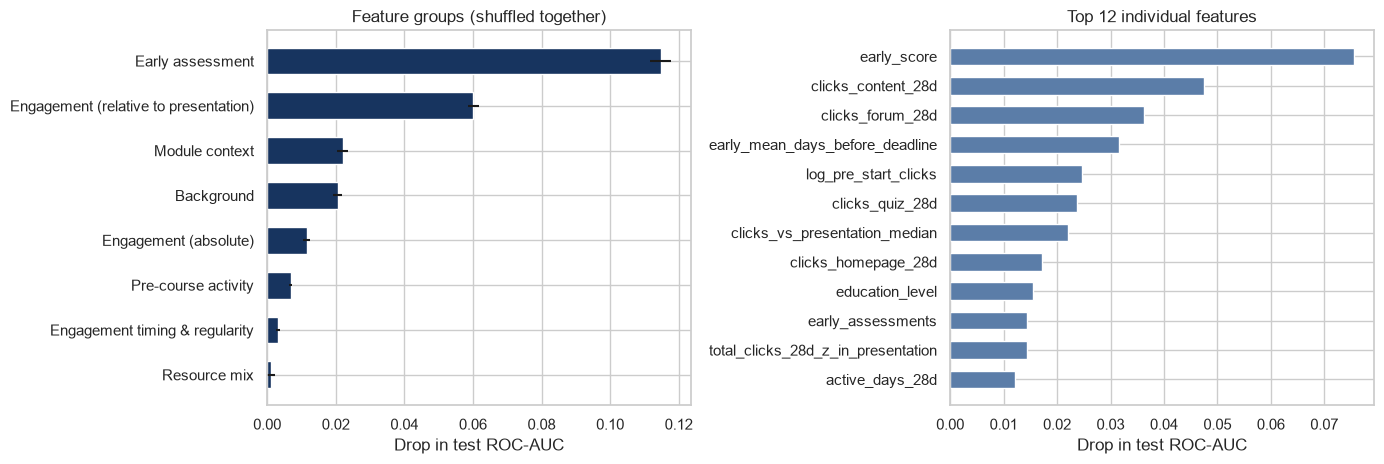

In [58]:
from sklearn.inspection import permutation_importance

X_test_final = test[FINAL_FEATURES]
baseline_auc = roc_auc_score(y_test, p_test)
rng = np.random.default_rng(RANDOM_STATE)
group_rows = []
for group, members in feature_groups.items():
    members = [f for f in members if f in FINAL_FEATURES]
    if not members:
        continue
    drops = []
    for _ in range(10):
        shuffled = X_test_final.copy()
        permutation = rng.permutation(len(shuffled))
        shuffled[members] = shuffled[members].to_numpy()[permutation]
        drops.append(baseline_auc - roc_auc_score(y_test, final_model.predict_proba(shuffled)[:, 1]))
    group_rows.append({"feature group": group, "features": len(members),
                       "ROC-AUC drop": np.mean(drops), "sd": np.std(drops)})
group_importance = pd.DataFrame(group_rows).sort_values("ROC-AUC drop", ascending=False).set_index("feature group")
display(group_importance.round(4))

single = permutation_importance(final_model, X_test_final, y_test, scoring="roc_auc",
                                n_repeats=5, random_state=RANDOM_STATE)
feature_importance = (
    pd.DataFrame({"feature": FINAL_FEATURES, "ROC-AUC drop": single.importances_mean,
                  "sd": single.importances_std})
    .sort_values("ROC-AUC drop", ascending=False).set_index("feature")
)
display(feature_importance.head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
gi = group_importance["ROC-AUC drop"]
axes[0].barh(gi.index, gi.values, xerr=group_importance["sd"], color="#17345F", height=0.6)
axes[0].invert_yaxis()
axes[0].set_title("Feature groups (shuffled together)")
axes[0].set_xlabel("Drop in test ROC-AUC")
top = feature_importance.head(12)["ROC-AUC drop"]
axes[1].barh(top.index, top.values, color="#5B7DA8", height=0.6)
axes[1].invert_yaxis()
axes[1].set_title("Top 12 individual features")
axes[1].set_xlabel("Drop in test ROC-AUC")
plt.tight_layout()
plt.show()

### 9.9 Hypotheses H1–H8 revisited
For each EDA hypothesis: the observed at-risk rate in the test presentations and the model's mean predicted
risk for the same groups. If the model has learned the relationship, the predicted risks follow the same order.

In [59]:
hv = test.assign(predicted=p_test)
hv["active_days_rank_band"] = pd.cut(hv["active_days_28d_pct_in_presentation"],
                                     [0, 1/3, 2/3, 1], labels=["bottom third", "middle third", "top third"])
hv["score_band"] = pd.cut(hv["early_mean_score_clean"], [-np.inf, 40, 60, 80, np.inf], right=False,
                          labels=["below 40", "40-59", "60-79", "80+"])
hv["attempt_band"] = pd.cut(hv["num_of_prev_attempts"], [-1, 0, 1, np.inf], labels=["0", "1", "2+"])
hv["credit_band"] = pd.cut(hv["studied_credits"], [-np.inf, 60, 120, 180, np.inf],
                           labels=["up to 60", "61-120", "121-180", "over 180"])
hv["submitted"] = np.select(
    [hv["has_early_assessment_opportunity"] == 0, hv["early_submissions"] > 0],
    ["no assessment due", "submitted"], default="did not submit")
hv["activity"] = np.where(hv["no_activity_28d"] == 1, "no activity", "some activity")

hypothesis_rows = []
for hid, column, levels in [
    ("H1", "active_days_rank_band", ["bottom third", "middle third", "top third"]),
    ("H2", "activity", ["no activity", "some activity"]),
    ("H3", "submitted", ["did not submit", "submitted"]),
    ("H4", "score_band", ["below 40", "40-59", "60-79", "80+"]),
    ("H5", "attempt_band", ["0", "1", "2+"]),
    ("H6", "credit_band", ["up to 60", "61-120", "121-180", "over 180"]),
]:
    for level in levels:
        part = hv[hv[column].astype("object") == level]
        hypothesis_rows.append({"hypothesis": hid, "group": level, "registrations": len(part),
                                "observed at-risk rate": part["at_risk"].mean(),
                                "mean predicted risk": part["predicted"].mean()})
hypothesis_check = pd.DataFrame(hypothesis_rows).set_index(["hypothesis", "group"])
display(hypothesis_check.round(3))
print(f"H7: test ROC-AUC by module ranges from {by_module['ROC-AUC'].min():.3f} "
      f"({by_module['ROC-AUC'].idxmin()}) to {by_module['ROC-AUC'].max():.3f} ({by_module['ROC-AUC'].idxmax()})")
print(f"H8: largest recall gap {fairness_gaps['recall_gap'].max():.3f} "
      f"({fairness_gaps['recall_gap'].idxmax()}), largest false-positive-rate gap "
      f"{fairness_gaps['fpr_gap'].max():.3f} ({fairness_gaps['fpr_gap'].idxmax()})")

registrations  observed at-risk rate  \
hypothesis group                                                  
H1         bottom third             3074                  0.603   
           middle third             3121                  0.382   
           top third                3024                  0.237   
H2         no activity               317                  0.798   
           some activity            8902                  0.394   
H3         did not submit            908                  0.806   
           submitted                6573                  0.368   
H4         below 40                  178                  0.882   
           40-59                     572                  0.680   
           60-79                    1865                  0.420   
           80+                      2317                  0.246   
H5         0                        8139                  0.385   
           1                         888                  0.583   
           2+                        192                  0.594   
H6         up to 60                 6241                  0.389   
           61-120                   2565                  0.432   
           121-180                   335                  0.525   
           over 180                   78                  0.628   

                           mean predicted risk  
hypothesis group                                
H1         bottom third                  0.583  
           middle third                  0.365  
           top third                     0.238  
H2         no activity                   0.809  
           some activity                 0.381  
H3         did not submit                0.828  
           submitted                     0.343  
H4         below 40                      0.875  
           40-59                         0.646  
           60-79                         0.417  
           80+                           0.229  
H5         0                             0.374  
           1                             0.560  
           2+                            0.566  
H6         up to 60                      0.380  
           61-120                        0.419  
           121-180                       0.483  
           over 180                      0.533

H7: test ROC-AUC by module ranges from 0.672 (GGG) to 0.803 (CCC)
H8: largest recall gap 0.263 (Previous education (grouped)), largest false-positive-rate gap 0.305 (Previous education (grouped))


In [60]:
# ---- 9.10  Summary ----
summary = pd.DataFrame({
    "value": {
        "Logistic regression baseline": f"{FINAL_FAMILY} {FINAL_PARAMS}",
        "Features": f"{len(FINAL_FEATURES)} (sensitive attributes {'excluded' if drop_sensitive else 'included'}, "
                    f"score features {'included' if keep_score else 'excluded'})",
        "Development / test registrations": f"{len(development):,} / {len(test):,}",
        "CV ROC-AUC (development)": mean_sd(final_cv_metrics)["ROC-AUC"],
        "Test ROC-AUC [95% CI]": f"{point['ROC-AUC']:.3f} [{final_ci.loc['ROC-AUC', '95% CI low']:.3f}, "
                                 f"{final_ci.loc['ROC-AUC', '95% CI high']:.3f}]",
        "Test PR-AUC": f"{point['PR-AUC']:.3f} (prevalence {y_test.mean():.3f})",
        "Threshold (from development)": f"{THRESHOLD:.3f}",
        "Test recall / precision / F1": f"{point['Recall']:.3f} / {point['Precision']:.3f} / {point['F1']:.3f}",
        "Test accuracy vs majority baseline": f"{point['Accuracy']:.3f} vs {1 - y_test.mean():.3f}",
        "Test ROC-AUC without score features": f"{roc_auc_score(y_test, test_probability['Sensitivity: without score features']):.3f}",
    }
})
display(summary)

,value
Logistic regression baseline,Logistic regression {'C': 1.0}
Features,"75 (sensitive attributes excluded, score features included)"
Development / test registrations,"18,334 / 9,219"
CV ROC-AUC (development),0.789 ± 0.003
Test ROC-AUC [95% CI],"0.763 [0.753, 0.774]"
Test PR-AUC,0.711 (prevalence 0.408)
Threshold (from development),0.360
Test recall / precision / F1,0.696 / 0.612 / 0.651
Test accuracy vs majority baseline,0.696 vs 0.592
Test ROC-AUC without score features,0.746


---
# Part 10 · Conclusions from feature engineering and modelling

*All numbers below are produced by the cells above (fixed random seed 42), so a Restart & Run All
reproduces them.*

**Unified table.** All seven OULAD tables were combined into one in-memory table, `model_table`
(27,553 registrations × 56 columns, no duplicate keys, nothing after day 27, no outcome or withdrawal-date
columns). The 33 columns it shares with the EDA handoff match it exactly.

**Features.** 80 candidate features in 8 groups. Engagement was expressed relative to the module
presentation (percentile ranks, z-scores of log-clicks, ratio to the presentation median), alongside
pre-course activity, the mix of resources used, regularity measures and early-assessment behaviour.
Structural gaps ("no assessment was due") were kept separate from zeros.

**Student dependency (8.1b–8.1c).** 2,583 of the 24,849 students have more than one registration, which
is 19.2% of all rows. Their outcomes are clearly linked. If one registration is at risk, the student's other
registration is at risk 70.9% of the time, against 36.2% if the other was successful (phi 0.35). The link is
strongest for modules taken in the same presentation (80.5% vs 22.9%, phi 0.58). Rows of the same student are
therefore not independent. Every cross-validation split keeps a student's rows together (0 students on both
sides of any fold), and the test-set confidence intervals resample students, not rows. Ignoring the grouping
would put about 356 students on both sides of each fold. Here that changes CV ROC-AUC only slightly
(0.7883 vs 0.7889), because most students have a single registration. Grouping is still the correct design.

**Model choice: all models on the same 75 features (cross-validation on 2013B/2013J/2014B).**
Every model was tuned on the same 75 features (all candidates except the 5 sensitive attributes). Gradient
boosting reached ROC-AUC 0.793, logistic regression 0.789, random forest 0.786 and the majority-class baseline
0.500. Gradient boosting and logistic regression are within 0.005, so by the pre-specified rule the simpler and
more explainable **logistic regression** was selected (C = 0.1). On the 2014J test set it also has the highest
accuracy of all models (0.696, against 0.665 for random forest and 0.673 for gradient boosting).

**With and without sensitive attributes, for every model.** Adding gender, disability, age and IMD (80
features) raises CV ROC-AUC by only 0.002–0.003 for each model: logistic regression 0.789 → 0.792, random
forest 0.786 → 0.788, gradient boosting 0.793 → 0.795. On the test set the gain is 0.002–0.004. The final
model therefore leaves them out (75 features). Without the early-score features (73 features), every model
loses about 0.026 ROC-AUC in CV and 0.018–0.024 on the test set.

**What the information adds (CV ROC-AUC).** Enrolment information alone: 0.661. Adding day-0–27
engagement: 0.755. Adding early assessment: 0.792. The early score adds 0.025 on top of submission behaviour.
*Relative vs raw engagement:* with module context in the model the two are equivalent (0.753 vs 0.754); without
module context, relative engagement is clearly better (0.747 vs 0.730). Within-presentation ranks therefore
carry the module context themselves, as the EDA suggested.

**Evaluation on the 2014J presentations (9,219 registrations).** After the professor's feedback, all models
were re-run on the same 75 features and scored on 2014J. The Logistic regression baseline was still chosen by the
cross-validation rule, not by the test results.

| Metric | Logistic regression baseline | Majority baseline |
|---|---|---|
| ROC-AUC [95% CI] | **0.765** [0.754, 0.776] | 0.500 |
| PR-AUC (prevalence 0.408) | 0.714 | 0.408 |
| Recall / precision / F1 at threshold 0.359 | 0.704 / 0.611 / 0.654 | 0 / 0 / 0 |
| Accuracy | 0.696 | 0.592 |

The model is well calibrated, and its predicted risks follow every EDA hypothesis (H1–H6) on the test set.
If advisers can only contact the 20% highest-risk registrations, 79% of those contacted are truly at risk,
and they include 39% of all at-risk students.

**Why test performance is lower than CV (0.765 vs 0.789).** The 2014J cohort has fewer at-risk students
(40.8% vs 45.8%). BBB_2014J's only early assessment (15020) carries no usable score, so BBB loses its
strongest signal (BBB test ROC-AUC 0.703). There is also ordinary drift between years: the model without
score features drops by a similar amount (0.762 → 0.747).

**By module (H7).** Test ROC-AUC ranges from 0.672 (GGG) to 0.804 (CCC). Performance is weakest where there
is no early assessment (GGG, EEE) or no usable score (BBB_2014J), and for the small AAA module. One general
model is adequate, but its scores should be read with module context in mind.

**Fairness (H8).** Discrimination is similar across groups: ROC-AUC differs by at most 0.044 for gender, age
and disability, and by 0.08 for IMD, where the "Unknown" group is lowest at 0.693. Error rates differ more,
mostly following base-rate differences. Students with qualifications below A level are flagged more often
(recall 0.789, false-positive rate 0.462) than students with HE or postgraduate qualifications (0.525, 0.145).
Men are flagged more often than women (recall 0.75 vs 0.63). These gaps should be monitored, and flags should
lead to supportive contact, not automated decisions.

**Limitations of the modelling stage.** The model was trained on four presentation periods of seven UK
modules. The grade-release timing of the early score is unknown, so the no-score model (test ROC-AUC 0.747)
is the conservative alternative. Logistic regression uses raw and log click counts as built; transforming
every count feature might help the linear model further, but this was not tried. Permutation importance
shows association with the predictions, not causation.